# Readmission 2026 — Extended Analysis (AACAP)

Tiered inferential analysis on the **complete cohort (N = 2,652 patients; per-patient 90-day (post-discharge)
readmission 9.3%)**, plus a **preliminary-subset** readmission-timing and provider analysis.

**Statistical tiers**
1. **Bivariate inferential** — each association with an explicit test + figure
2. **Subgroup descriptive** — diagnosis subgroups (visit / chronic / non-suicidal) vs four outcomes
3. **Multivariate inferential** — adjusted logistic & linear regression
4. **Readmission windows & readmission LOS** — *preliminary subset* (XLSX, N≈1,920; 1,206 linked)
5. **Psychiatrist vs NP** — *preliminary subset*, exploratory (n=26 NP)
6. **ML / predictive** — Random Forest & CatBoost with new features

> Tests follow the project's idioms: Mann-Whitney U (skewed LOS / continuous-by-group), Spearman
> (continuous-continuous), chi-square (categorical), Kruskal-Wallis (>2 groups), `statsmodels`
> logistic/OLS for adjusted models. Multi-hypothesis families are FDR (Benjamini-Hochberg) corrected.
> LOS is right-skewed, so medians (IQR) and non-parametric tests are primary.


In [1]:
# ── Imports & style ──────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import os, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

plt.rcParams.update({'font.size':12,'axes.titlesize':14,'figure.dpi':120,'savefig.dpi':200,'savefig.bbox':'tight'})
BLUE, ORANGE, GREEN, RED, PURPLE = '#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3'
sns.set_style('whitegrid')
os.makedirs('figures', exist_ok=True)
ROOT = '.'
print('✓ libraries loaded')

✓ libraries loaded


## Preamble — load complete cohort & engineer features
(mirrors Part 1; this notebook stands alone)

In [ ]:
# ── Load complete cohort (N=2,652) + feature engineering ─────────────────────
df = pd.read_csv('annotated_psychiatric_data_complete.csv')
df['readmitted'] = (pd.to_numeric(df['Readmissions'], errors='coerce').fillna(0) > 0).astype(int)
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['gender'] = df['GenderCode'].str.strip().str.title()
df['gender_male'] = (df['GenderCode'].str.strip().str.lower()=='male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)
df['insurance_cat'] = np.where(df['insurance_public']==1,'Public (AHCCCS)','Commercial/Other')
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score']>=4).astype(float)
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['had_restraints'] = (df['restraint_n']>0).astype(int)
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)   # NOTE: 'C-SRSS' typo is in the source CSV
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow']+df['csrss_orange']+df['csrss_red'])>0).astype(int)
df['csrss_level']  = np.select([df['csrss_red']==1, df['csrss_orange']==1, df['csrss_yellow']==1],[3,2,1],default=0)
df['csrss_label']  = df['csrss_level'].map({0:'None',1:'Yellow',2:'Orange',3:'Red'})
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate'] = pd.to_datetime(df['DischDate'], errors='coerce')
df['los_days']  = (df['DischDate']-df['VisitDate']).dt.days

def count_csv(s):
    return 0 if pd.isna(s) or str(s).strip()=='' else len([x for x in str(s).split(',') if x.strip()])
def uniq_dsm5(row):
    cats=set()
    for col in ['VisitDiags_DSM5Categories','ChronicDiags_DSM5Categories']:
        v=row.get(col,'')
        if pd.notna(v) and str(v).strip(): cats.update(c.strip() for c in str(v).split(';') if c.strip())
    return len(cats)
df['n_dsm5_categories'] = df.apply(uniq_dsm5, axis=1)
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('')+';'+df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()
CATEGORY_FLAGS = {'has_nssi':'non-suicidal self-injury','has_trauma':'trauma and stressor','has_adhd':'adhd',
 'has_asd':'autism spectrum','has_conduct':'conduct disorder','has_depression':'depressive disorders',
 'has_anxiety':'anxiety disorders','has_bipolar':'bipolar','has_psychotic':'psychotic',
 'has_intellectual':'intellectual disability','has_ocd':'obsessive-compulsive'}
for f,kw in CATEGORY_FLAGS.items(): df[f]=all_dsm5.str.contains(kw,na=False).astype(int)

# Part B: neurocognitive flag (organic codes that PyHealth CCS routes to 'residual; unclassified')
NEURO_CODES = ['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
allcodes = (df['VisitDiags'].fillna('')+','+df['ChronicDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')).str.upper()
df['has_neurocognitive'] = (all_dsm5.str.contains('neurocognitive',na=False) |
                            allcodes.apply(lambda s: any(c in s for c in NEURO_CODES))).astype(int)

# Suicidality measured via ICD CODE (R45.851 suicidal ideation) — the operationalization the original
# 2025 analysis used. This is DISTINCT from the C-SSRS flag columns (csrss_*), which capture a
# different construct; the two are analyzed separately throughout. A suicide-attempt/history flag is
# also derived (T14.91 self-harm injury; Z91.5 personal history of self-harm).
df['has_suicidal_ideation'] = allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)

# ── Diagnostic complexity — TWO distinct measures (these are NOT the same thing) ──────────────
#   n_dsm5_categories   = number of distinct DSM-5 *categories* (e.g. 'Depressive Disorders') — coarse
#   n_distinct_diagnoses = number of distinct *ICD-10 codes* across all three diagnosis columns — granular
def _distinct_codes(row):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=row.get(col,'')
        if pd.notna(v) and str(v).strip():
            s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)

# ── Medical comorbidity (Feudtner Pediatric CCC-aligned) ────────────────────────────────────
# Allowlist of ICD-10 chapters that correspond to Feudtner CCC categories (BMC Pediatrics 2014):
#   C=Neoplasm, D=Blood, E=Endocrine/metabolic, G=Neurological, H=Eye/ear,
#   I=Cardiovascular, J=Respiratory, K=Digestive, L=Skin, M=Musculoskeletal,
#   N=Genitourinary, Q=Congenital.
# Excludes: F (psychiatric), Z (social/admin proxies), R (symptoms/signs — unconfirmed),
#   A/B (infectious — typically acute), P (perinatal), S/T/V-Y (injury/external cause).
_CCC_CHAPTERS = frozenset('CDEGHIJKLMNQ')
def _has_ccc(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return 0
    tokens = [t.strip().upper() for t in str(codes).split(',') if t.strip()]
    return int(any(t and t[0] in _CCC_CHAPTERS for t in tokens))
df['has_medical_comorbidity'] = df['ChronicDiags'].apply(_has_ccc)

# ── ACE-Associated Health Conditions (ACEs Aware pediatric algorithm) ────────────────────────
#   Physical/somatic AAHCs detectable by ICD prefix. We deliberately EXCLUDE the psychiatric AAHCs
#   (depression/ADHD/anxiety/conduct/suicidal ideation) because in this psychiatric inpatient cohort
#   they are near-universal (~96%) and are the admission diagnoses themselves — including them would
#   make 'high ACE' circular and ~90% prevalent. Physical AAHCs give a meaningful ~33% flag.
PHYS_AAHC = {
 'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),
 'Failure to thrive':('R6251','R627','R633'),
}
_norm = allcodes.str.replace('.','',regex=False)
def _has_prefix(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
ace_cond_flags = pd.DataFrame({name:_has_prefix(pfx) for name,pfx in PHYS_AAHC.items()})
df['has_ace_condition'] = (ace_cond_flags.sum(axis=1)>0).astype(int)               # physical AAHC present
# full-list version (incl. psychiatric AAHCs) — kept only to demonstrate why it is unusable here
df['has_ace_condition_full'] = ((df['has_ace_condition']==1) |
    allcodes.str.contains('F32|F33|F34|F40|F41|F90|F91|R45.851', regex=True)).astype(int)

# ACEs Aware PEDIATRIC risk tier: Low=ACE 0; High=ACE>=4 OR (ACE 1-3 WITH a physical AAHC);
# Intermediate=ACE 1-3 without. (Computed only where ACE is recorded.)
def _ace_tier(a, cond):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if cond==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})   # NaN where ACE missing

N=len(df)
print(f'N={N} | readmit={df.readmitted.sum()} ({df.readmitted.mean()*100:.1f}%) | ACE avail={df.ace_score.notna().sum()} '
      f'| LOS median={df.los_days.median():.0f} | neurocognitive={df.has_neurocognitive.sum()} '
      f'| suicidal-ideation(ICD)={df.has_suicidal_ideation.sum()} ({df.has_suicidal_ideation.mean()*100:.0f}%)')

In [3]:
# ── Statistical helpers ──────────────────────────────────────────────────────
def pstr(p): return '<0.001' if (pd.notna(p) and p<0.001) else (f'{p:.3f}' if pd.notna(p) else 'n/a')
def mwu(a,b):
    a=pd.Series(a).dropna(); b=pd.Series(b).dropna()
    if len(a)<3 or len(b)<3: return dict(n1=len(a),n2=len(b),med1=a.median(),med2=b.median(),U=np.nan,p=np.nan)
    U,p=stats.mannwhitneyu(a,b,alternative='two-sided')
    return dict(n1=len(a),n2=len(b),med1=a.median(),med2=b.median(),U=U,p=p)
def spear(a,b):
    d=pd.DataFrame({'a':a,'b':b}).dropna()
    r,p=stats.spearmanr(d['a'],d['b']); return dict(n=len(d),rho=r,p=p)
def chi2(a,b):
    tab=pd.crosstab(a,b); c,p,dof,_=stats.chi2_contingency(tab); return dict(p=p,chi2=c,dof=dof,tab=tab)
def kruskal(groups):
    gs=[pd.Series(g).dropna() for g in groups]; gs=[g for g in gs if len(g)>=3]
    H,p=stats.kruskal(*gs); return dict(H=H,p=p,k=len(gs))
def odds_ratio_2x2(flag, outcome):
    # logistic univariate OR for binary flag vs binary outcome
    try:
        m=smf.logit(f'{outcome} ~ flag', data=pd.DataFrame({'flag':flag.astype(float),outcome:df[outcome].values})).fit(disp=0)
        return np.exp(m.params['flag']), m.pvalues['flag']
    except Exception:
        return np.nan, np.nan
print('✓ helpers ready')

✓ helpers ready


## §1 — Bivariate inferential analyses
Each association has a test and a figure; the diagnosis↔LOS family is FDR-corrected.

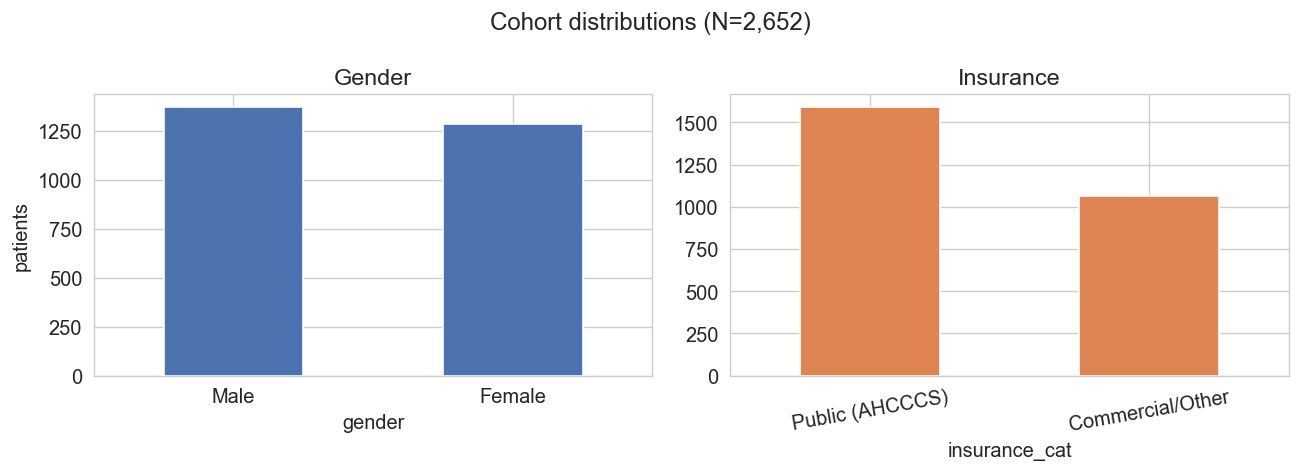

Gender: {'Male': np.int64(1369), 'Female': np.int64(1283)} | Insurance: {'Public (AHCCCS)': np.int64(1589), 'Commercial/Other': np.int64(1063)}


In [4]:
# 1. Gender & insurance distributions
fig,ax=plt.subplots(1,2,figsize=(11,4))
df['gender'].value_counts().plot.bar(ax=ax[0],color=BLUE); ax[0].set_title('Gender'); ax[0].set_ylabel('patients'); ax[0].tick_params(axis='x',rotation=0)
df['insurance_cat'].value_counts().plot.bar(ax=ax[1],color=ORANGE); ax[1].set_title('Insurance'); ax[1].tick_params(axis='x',rotation=10)
plt.suptitle('Cohort distributions (N=2,652)'); plt.tight_layout(); plt.savefig('figures/Biv_01_distributions.png'); plt.show()
print('Gender:',dict(df.gender.value_counts()),'| Insurance:',dict(df.insurance_cat.value_counts()))

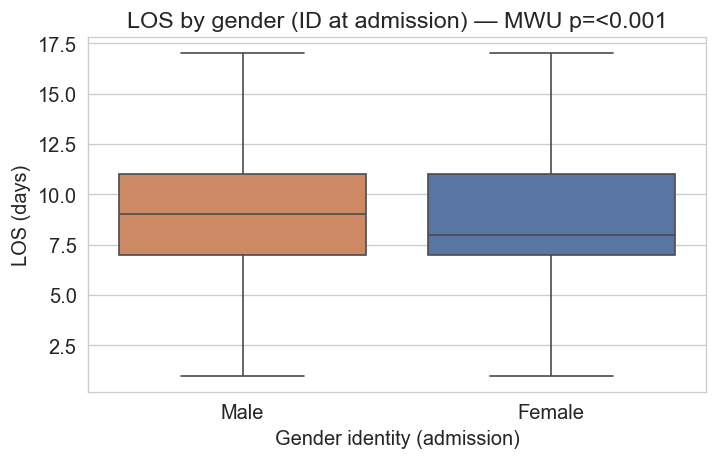

Male median LOS=9 (n=1369) vs Female=8 (n=1283); MWU p=<0.001


In [5]:
# 2. LOS by gender identity at admission (GenderCode = gender ID, not sex) — Mann-Whitney
r=mwu(df[df.gender_male==1].los_days, df[df.gender_male==0].los_days)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='gender',y='los_days',ax=ax,showfliers=False,palette=[ORANGE,BLUE])
ax.set_title(f'LOS by gender (ID at admission) — MWU p={pstr(r["p"])}'); ax.set_xlabel('Gender identity (admission)'); ax.set_ylabel('LOS (days)'); plt.tight_layout(); plt.savefig('figures/Biv_02_los_by_sex.png'); plt.show()
print(f'Male median LOS={r["med1"]:.0f} (n={r["n1"]}) vs Female={r["med2"]:.0f} (n={r["n2"]}); MWU p={pstr(r["p"])}')

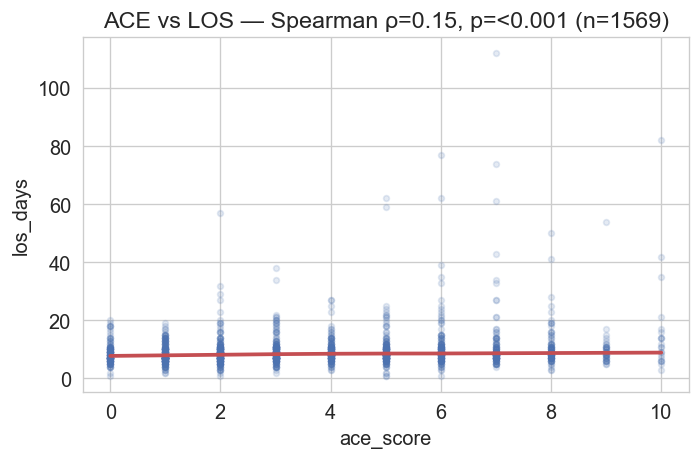

ACE~LOS Spearman rho=0.148, p=<0.001, n=1569


In [6]:
# 3. ACE vs LOS (Spearman)
r=spear(df.ace_score, df.los_days)
d=df.dropna(subset=['ace_score','los_days'])
fig,ax=plt.subplots(figsize=(6,4)); sns.regplot(data=d,x='ace_score',y='los_days',lowess=True,scatter_kws=dict(alpha=.15,s=12,color=BLUE),line_kws=dict(color=RED),ax=ax)
ax.set_title(f'ACE vs LOS — Spearman ρ={r["rho"]:.2f}, p={pstr(r["p"])} (n={r["n"]})'); plt.tight_layout(); plt.savefig('figures/Biv_03_ace_los.png'); plt.show()
print(f'ACE~LOS Spearman rho={r["rho"]:.3f}, p={pstr(r["p"])}, n={r["n"]}')

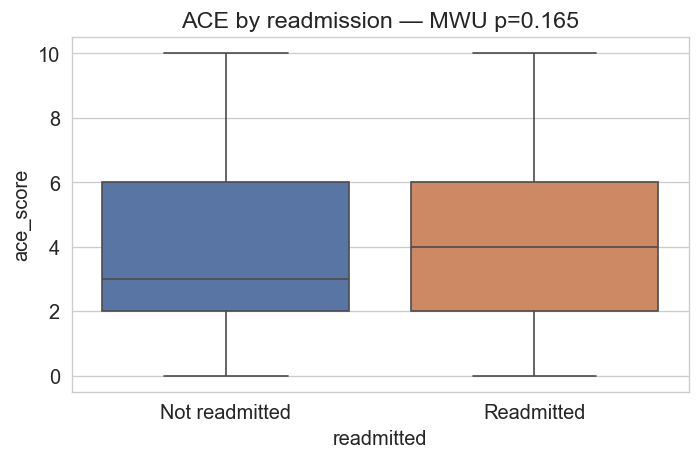

ACE readmitted median=4.0 vs not=3.0; MWU p=0.165


In [7]:
# 4. ACE in readmitted vs not (Mann-Whitney)
r=mwu(df[df.readmitted==1].ace_score, df[df.readmitted==0].ace_score)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='readmitted',y='ace_score',ax=ax,showfliers=False,palette=[BLUE,ORANGE])
ax.set_xticklabels(['Not readmitted','Readmitted']); ax.set_title(f'ACE by readmission — MWU p={pstr(r["p"])}'); plt.tight_layout(); plt.savefig('figures/Biv_04_ace_readmit.png'); plt.show()
print(f'ACE readmitted median={r["med1"]:.1f} vs not={r["med2"]:.1f}; MWU p={pstr(r["p"])}')

Suicidality measured two ways (readmission) — the ICD code is the original analysis's operationalization:
                        measure  prevalence_%  readmit_with_%  readmit_without_%  univariate_OR      p
Suicidal ideation (ICD R45.851)          50.8            11.4                7.1           1.67 <0.001
                Any C-SSRS flag          32.4             9.4                9.2           1.03  0.861


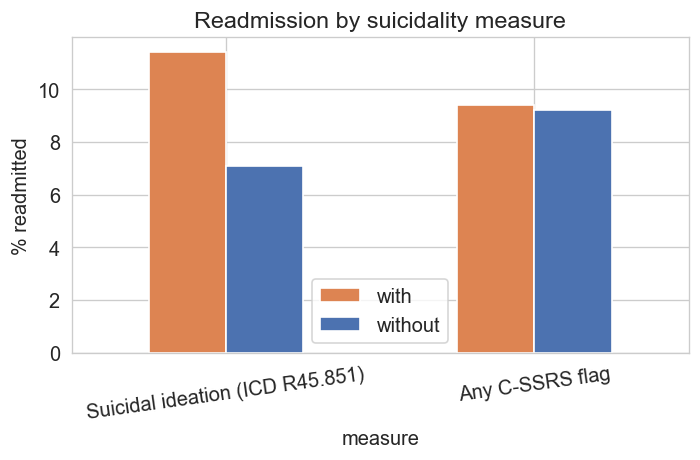

In [8]:
# 4b. Suicidality — ICD code (R45.851 ideation) vs C-SSRS flag: DIFFERENT constructs, opposite signals
si=odds_ratio_2x2(df['has_suicidal_ideation'],'readmitted'); cf=odds_ratio_2x2(df['csrss_any'],'readmitted')
rates=pd.DataFrame({
 'measure':['Suicidal ideation (ICD R45.851)','Any C-SSRS flag'],
 'prevalence_%':[round(df.has_suicidal_ideation.mean()*100,1),round(df.csrss_any.mean()*100,1)],
 'readmit_with_%':[round(df[df.has_suicidal_ideation==1].readmitted.mean()*100,1),round(df[df.csrss_any==1].readmitted.mean()*100,1)],
 'readmit_without_%':[round(df[df.has_suicidal_ideation==0].readmitted.mean()*100,1),round(df[df.csrss_any==0].readmitted.mean()*100,1)],
 'univariate_OR':[round(si[0],2),round(cf[0],2)],'p':[pstr(si[1]),pstr(cf[1])]})
rates.to_csv('figures/Biv_04b_suicidality_measures.csv',index=False)
print('Suicidality measured two ways (readmission) — the ICD code is the original analysis\'s operationalization:')
print(rates.to_string(index=False))
fig,ax=plt.subplots(figsize=(6,4))
rates.set_index('measure')[['readmit_with_%','readmit_without_%']].plot.bar(ax=ax,color=[ORANGE,BLUE])
ax.set_ylabel('% readmitted'); ax.set_title('Readmission by suicidality measure'); ax.tick_params(axis='x',rotation=8); ax.legend(['with','without'])
plt.tight_layout(); plt.savefig('figures/Biv_04b_suicidality_measures.png'); plt.show()

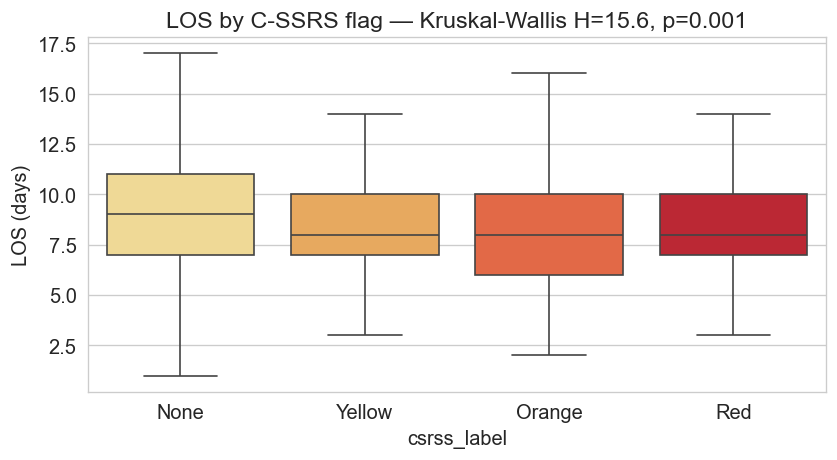

Median LOS by C-SSRS: {0: np.float64(9.0), 1: np.float64(8.0), 2: np.float64(8.0), 3: np.float64(8.0)} | KW p= 0.001


In [9]:
# 5 & 11. LOS by C-SSRS level (Kruskal-Wallis)
r=kruskal([df[df.csrss_level==l].los_days for l in [0,1,2,3]])
fig,ax=plt.subplots(figsize=(7,4)); sns.boxplot(data=df,x='csrss_label',y='los_days',order=['None','Yellow','Orange','Red'],ax=ax,showfliers=False,palette='YlOrRd')
ax.set_title(f'LOS by C-SSRS flag — Kruskal-Wallis H={r["H"]:.1f}, p={pstr(r["p"])}'); ax.set_ylabel('LOS (days)'); plt.tight_layout(); plt.savefig('figures/Biv_05_los_cssrs.png'); plt.show()
print('Median LOS by C-SSRS:',{df.csrss_label.map({0:"None"}).iloc[0] if False else l:round(df[df.csrss_level==l].los_days.median(),1) for l in [0,1,2,3]},'| KW p=',pstr(r['p']))

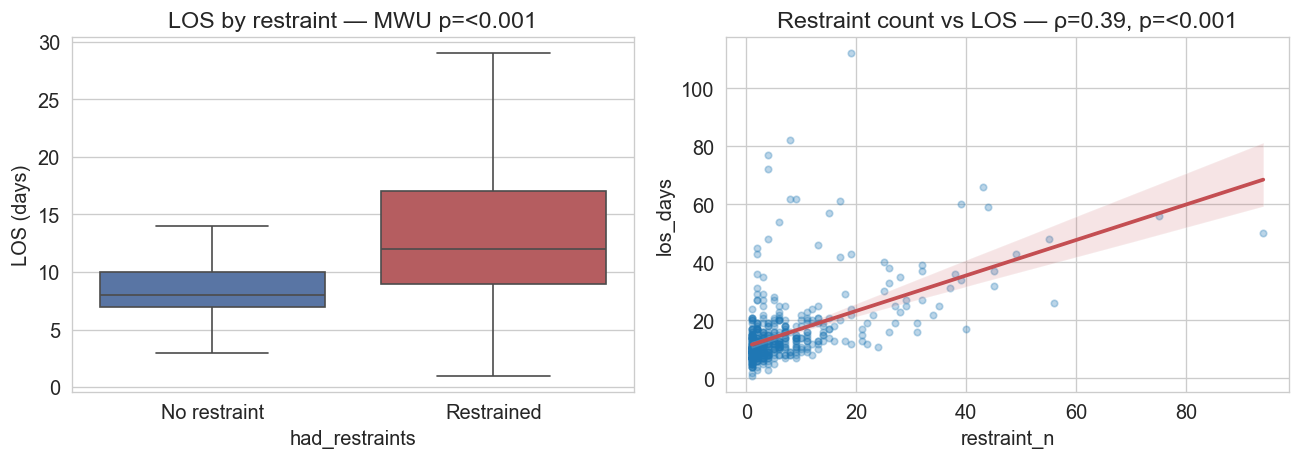

LOS restrained median=12 vs not=8, MWU p=<0.001; Spearman(count,LOS) rho=0.386, p=<0.001


In [10]:
# 6. Restraint vs LOS (Mann-Whitney + Spearman on count)
r1=mwu(df[df.had_restraints==1].los_days, df[df.had_restraints==0].los_days)
r2=spear(df.restraint_n, df.los_days)
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=df,x='had_restraints',y='los_days',ax=ax[0],showfliers=False,palette=[BLUE,RED]); ax[0].set_xticklabels(['No restraint','Restrained']); ax[0].set_title(f'LOS by restraint — MWU p={pstr(r1["p"])}'); ax[0].set_ylabel('LOS (days)')
d=df[df.restraint_n>0]; sns.regplot(data=d,x='restraint_n',y='los_days',scatter_kws=dict(alpha=.3,s=15),line_kws=dict(color=RED),ax=ax[1]); ax[1].set_title(f'Restraint count vs LOS — ρ={r2["rho"]:.2f}, p={pstr(r2["p"])}')
plt.tight_layout(); plt.savefig('figures/Biv_06_restraint_los.png'); plt.show()
print(f'LOS restrained median={r1["med1"]:.0f} vs not={r1["med2"]:.0f}, MWU p={pstr(r1["p"])}; Spearman(count,LOS) rho={r2["rho"]:.3f}, p={pstr(r2["p"])}')

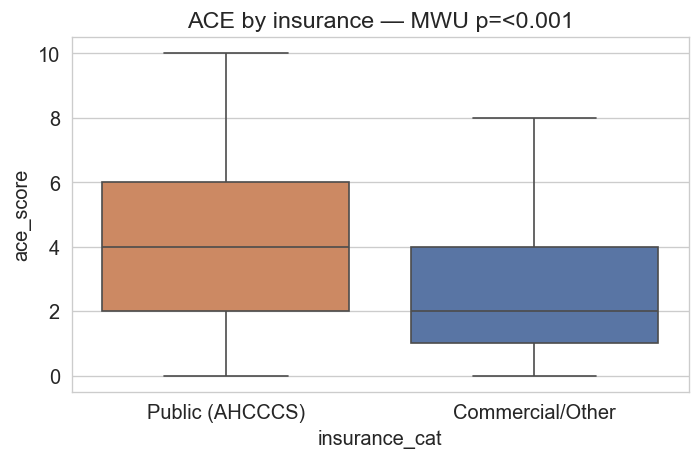

ACE public median=4.0 (n=960) vs commercial/other=2.0 (n=609); MWU p=<0.001


In [11]:
# 7. ACE by insurance (Mann-Whitney)
r=mwu(df[df.insurance_public==1].ace_score, df[df.insurance_public==0].ace_score)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='insurance_cat',y='ace_score',ax=ax,showfliers=False,palette=[ORANGE,BLUE]); ax.set_title(f'ACE by insurance — MWU p={pstr(r["p"])}'); plt.tight_layout(); plt.savefig('figures/Biv_07_ace_insurance.png'); plt.show()
print(f'ACE public median={r["med1"]:.1f} (n={r["n1"]}) vs commercial/other={r["med2"]:.1f} (n={r["n2"]}); MWU p={pstr(r["p"])}')

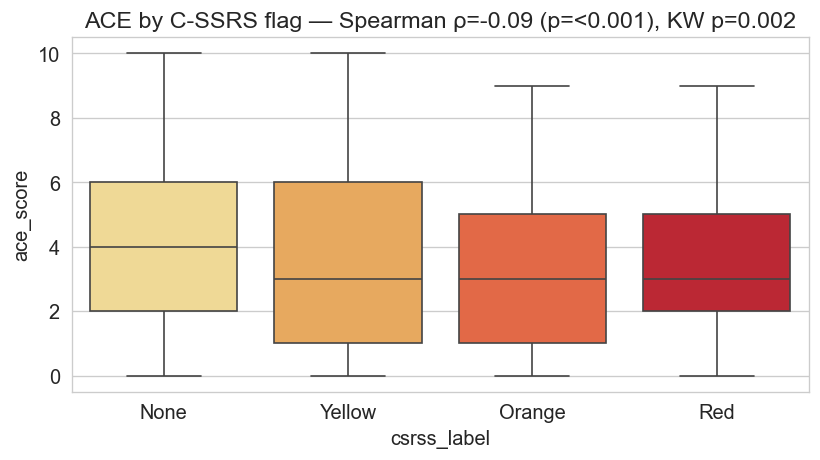

ACE~CSSRS Spearman rho=-0.091 p=<0.001; Kruskal p=0.002


In [12]:
# 8. ACE vs C-SSRS level (Spearman + Kruskal)
rs=spear(df.ace_score, df.csrss_level); rk=kruskal([df[df.csrss_level==l].ace_score for l in [0,1,2,3]])
fig,ax=plt.subplots(figsize=(7,4)); sns.boxplot(data=df,x='csrss_label',y='ace_score',order=['None','Yellow','Orange','Red'],ax=ax,showfliers=False,palette='YlOrRd'); ax.set_title(f'ACE by C-SSRS flag — Spearman ρ={rs["rho"]:.2f} (p={pstr(rs["p"])}), KW p={pstr(rk["p"])}'); plt.tight_layout(); plt.savefig('figures/Biv_08_ace_cssrs.png'); plt.show()
print(f'ACE~CSSRS Spearman rho={rs["rho"]:.3f} p={pstr(rs["p"])}; Kruskal p={pstr(rk["p"])}')

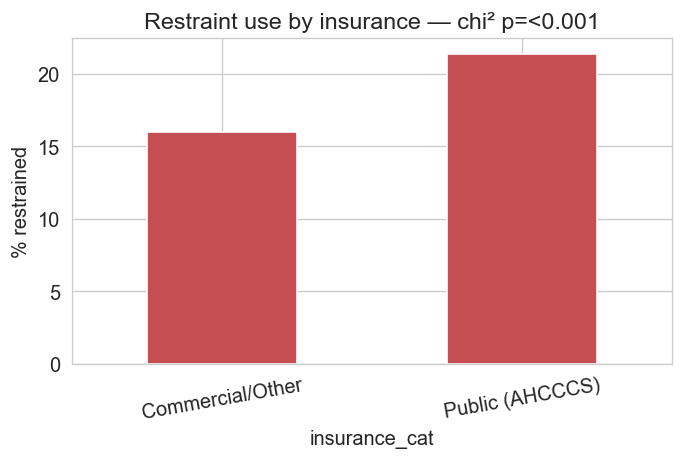

Restraint×insurance chi² p=<0.001; % restrained: {'Commercial/Other': np.float64(16.0), 'Public (AHCCCS)': np.float64(21.4)}


In [13]:
# 9. Restraint x insurance (chi-square)
r=chi2(df.had_restraints, df.insurance_cat)
ct=pd.crosstab(df.insurance_cat, df.had_restraints, normalize='index')*100
fig,ax=plt.subplots(figsize=(6,4)); ct[1].plot.bar(ax=ax,color=RED); ax.set_ylabel('% restrained'); ax.set_title(f'Restraint use by insurance — chi² p={pstr(r["p"])}'); ax.tick_params(axis='x',rotation=10); plt.tight_layout(); plt.savefig('figures/Biv_09_restraint_insurance.png'); plt.show()
print(f'Restraint×insurance chi² p={pstr(r["p"])}; % restrained:',dict((ct[1]).round(1)))

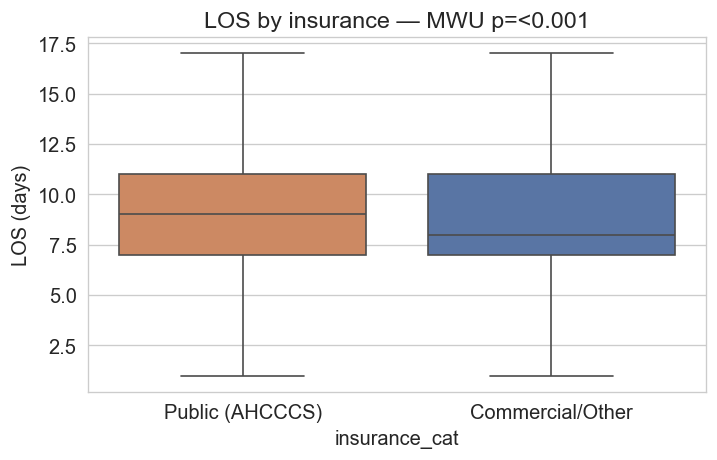

LOS public median=9 vs commercial/other=8; MWU p=<0.001


In [14]:
# 10. Insurance vs LOS (Mann-Whitney)
r=mwu(df[df.insurance_public==1].los_days, df[df.insurance_public==0].los_days)
fig,ax=plt.subplots(figsize=(6,4)); sns.boxplot(data=df,x='insurance_cat',y='los_days',ax=ax,showfliers=False,palette=[ORANGE,BLUE]); ax.set_title(f'LOS by insurance — MWU p={pstr(r["p"])}'); ax.set_ylabel('LOS (days)'); plt.tight_layout(); plt.savefig('figures/Biv_10_los_insurance.png'); plt.show()
print(f'LOS public median={r["med1"]:.0f} vs commercial/other={r["med2"]:.0f}; MWU p={pstr(r["p"])}')

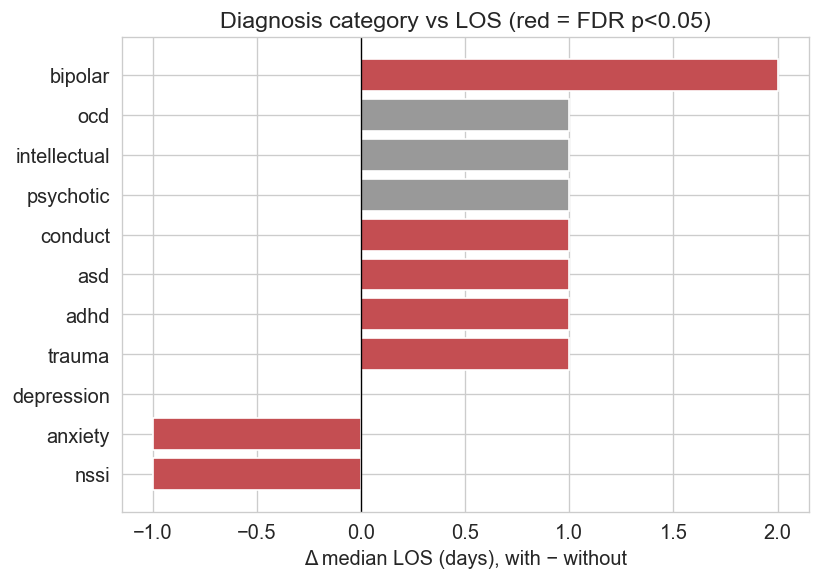

    category  n_with  delta            p        p_fdr
        nssi     966   -1.0 1.003370e-08 5.518534e-08
     anxiety    1154   -1.0 3.091773e-05 8.502375e-05
  depression    1779    0.0 9.037008e-01 9.037008e-01
      trauma    1424    1.0 4.637061e-05 1.020153e-04
        adhd    1399    1.0 1.033901e-16 1.137291e-15
         asd     513    1.0 8.624925e-08 3.162473e-07
     conduct     484    1.0 4.303870e-04 6.763225e-04
   psychotic      55    1.0 4.034341e-01 4.930861e-01
intellectual      57    1.0 1.909325e-01 2.625322e-01
         ocd     114    1.0 5.131705e-01 5.644875e-01
     bipolar     147    2.0 3.489028e-04 6.396552e-04


In [15]:
# 12. Diagnosis (DSM-5 category) vs LOS — FDR-corrected, forest of median differences
rows=[]
for f,kw in CATEGORY_FLAGS.items():
    r=mwu(df[df[f]==1].los_days, df[df[f]==0].los_days)
    rows.append(dict(category=f.replace('has_',''), n_with=r['n1'], med_with=r['med1'], med_without=r['med2'], delta=r['med1']-r['med2'], p=r['p']))
dd=pd.DataFrame(rows); dd['p_fdr']=multipletests(dd['p'],method='fdr_bh')[1]; dd=dd.sort_values('delta')
dd.to_csv('figures/Biv_12_diagnosis_los.csv', index=False)
fig,ax=plt.subplots(figsize=(7,5))
colors=[RED if (s<0.05) else '0.6' for s in dd['p_fdr']]
ax.barh(dd['category'], dd['delta'], color=colors); ax.axvline(0,color='k',lw=.8)
ax.set_xlabel('Δ median LOS (days), with − without'); ax.set_title('Diagnosis category vs LOS (red = FDR p<0.05)')
plt.tight_layout(); plt.savefig('figures/Biv_12_diagnosis_los.png'); plt.show()
print(dd[['category','n_with','delta','p','p_fdr']].to_string(index=False))

## §2 — Subgroup descriptive statistics
For each diagnosis column (**Visit**, **Chronic**, **Non-suicidal**), DSM-5 category subgroups
(n≥30) are described against four outcomes: **readmission** (rate + univariate OR), **LOS**
(median Δ), **ACE** (mean Δ), and **restraint** (rate + OR). FDR-corrected per outcome; forest
panels mark associated vs not.

In [16]:
# Build per-column DSM-5 category subgroup flags, then describe vs 4 outcomes
DIAG_COLS = {'Visit':'VisitDiags_DSM5Categories','Chronic':'ChronicDiags_DSM5Categories','NonSuicidal':'NonSuicidialDiags_DSM5Categories'}
KWS = {'NSSI':'non-suicidal self-injury','Trauma/Stressor':'trauma and stressor','ADHD':'adhd',
       'ASD':'autism spectrum','Conduct':'conduct disorder','Depressive':'depressive disorders',
       'Anxiety':'anxiety disorders','Bipolar':'bipolar','Psychotic':'psychotic'}
rows=[]
for colname, col in DIAG_COLS.items():
    if col not in df.columns: continue
    series = df[col].fillna('').str.lower()
    for label, kw in KWS.items():
        flag = series.str.contains(kw, na=False).astype(int)
        n = int(flag.sum())
        if n < 30: continue
        with_, without = df[flag==1], df[flag==0]
        rr_with = with_['readmitted'].mean()*100; rr_wo = without['readmitted'].mean()*100
        or_re,p_re = odds_ratio_2x2(flag,'readmitted')
        los = mwu(with_.los_days, without.los_days)
        ace = mwu(with_.ace_score, without.ace_score)
        or_rs,p_rs = odds_ratio_2x2(flag,'had_restraints')
        rows.append(dict(column=colname, subgroup=label, n=n,
            readmit_pct=round(rr_with,1), readmit_OR=round(or_re,2), p_readmit=p_re,
            dLOS=los['med1']-los['med2'], p_los=los['p'],
            dACE=(ace['med1']-ace['med2']), p_ace=ace['p'],
            restraint_OR=round(or_rs,2), p_restraint=p_rs))
sub=pd.DataFrame(rows)
for outcome,pcol in [('readmit','p_readmit'),('los','p_los'),('ace','p_ace'),('restraint','p_restraint')]:
    sub[f'{pcol}_fdr']=multipletests(sub[pcol].fillna(1),method='fdr_bh')[1]
sub.to_csv('figures/Sub_subgroup_outcomes.csv', index=False)
print(sub.to_string(index=False))

     column        subgroup    n  readmit_pct  readmit_OR    p_readmit  dLOS        p_los  dACE        p_ace  restraint_OR  p_restraint  p_readmit_fdr    p_los_fdr    p_ace_fdr  p_restraint_fdr
      Visit            NSSI  946          8.1        0.81 1.336011e-01  -1.0 2.518295e-09  -1.0 2.397021e-02          0.30 2.609021e-21   1.952632e-01 1.196190e-08 5.060378e-02     1.652380e-20
      Visit Trauma/Stressor 1212          8.7        0.87 3.186687e-01   1.0 4.511608e-03   3.0 2.716018e-45          0.91 3.693864e-01   4.036470e-01 7.143379e-03 2.580217e-44     4.039758e-01
      Visit            ADHD 1047         10.1        1.18 2.243587e-01   1.0 3.790421e-11   1.0 2.247860e-01          2.70 8.038444e-23   3.044868e-01 3.600900e-10 3.621302e-01     7.636522e-22
      Visit             ASD  279         10.4        1.15 4.964049e-01   1.0 1.911845e-03  -1.0 1.912533e-05          1.71 2.035258e-04   5.825027e-01 3.302277e-03 6.056354e-05     3.222492e-04
      Visit         Conduct  3

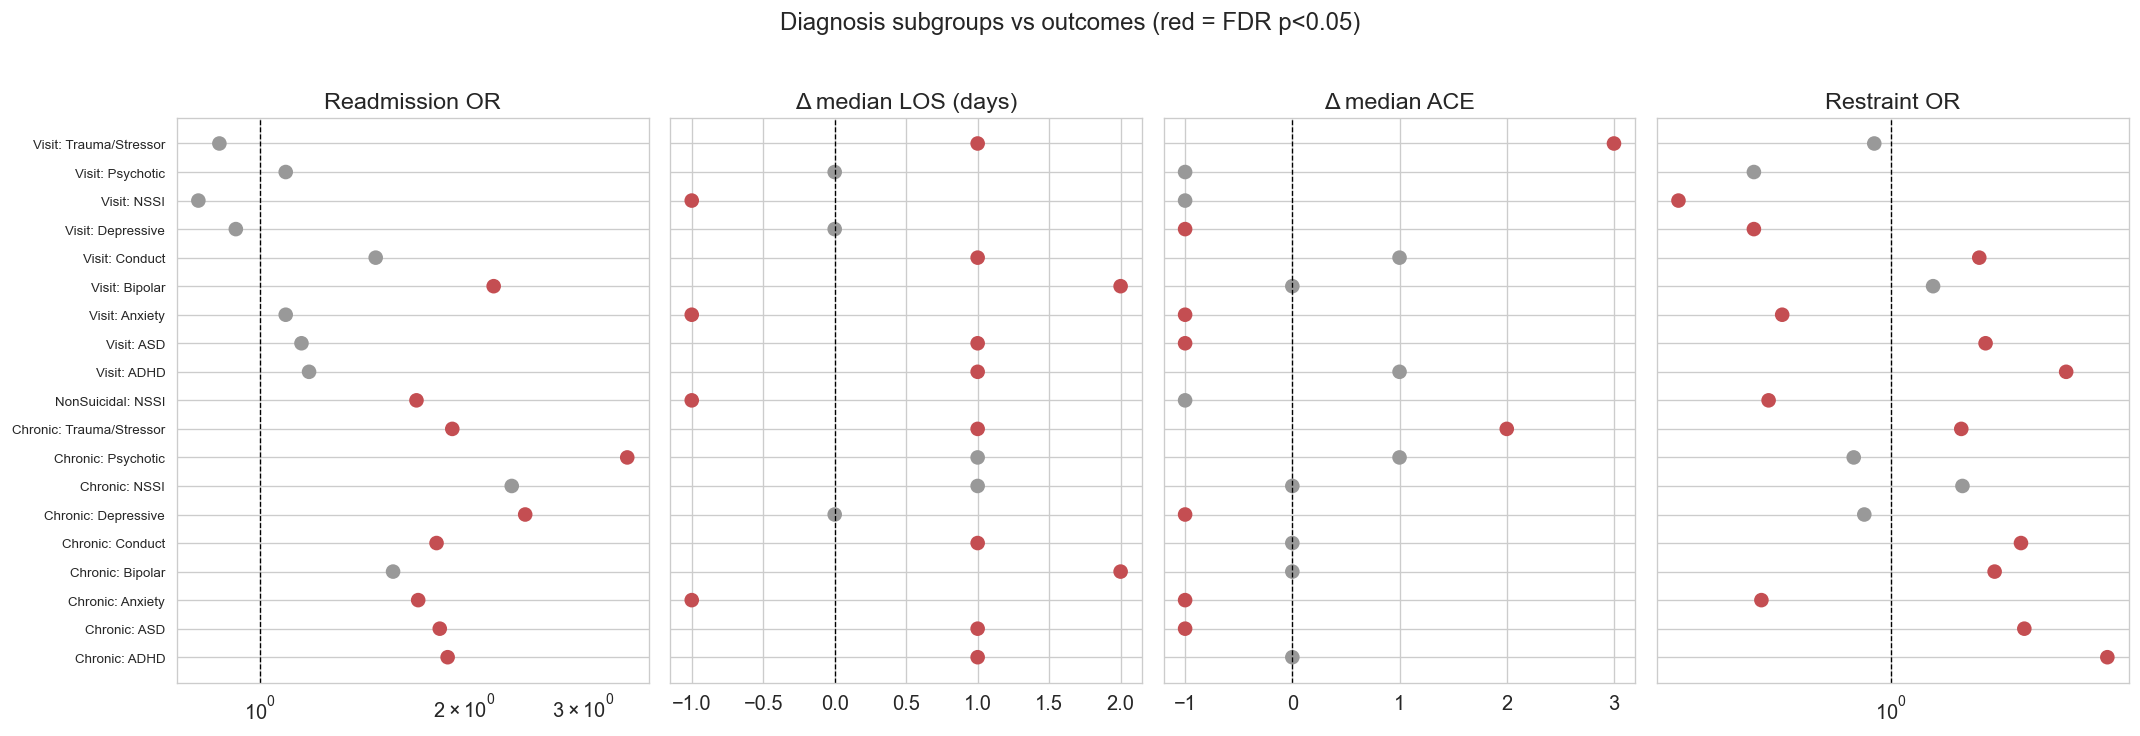

saved Sub_forest_panels.png


In [17]:
# Forest panels: subgroup vs each outcome (label = column:subgroup)
sub['lab']=sub['column']+': '+sub['subgroup']
panels=[('readmit_OR','p_readmit_fdr','Readmission OR',True),
        ('dLOS','p_los_fdr','Δ median LOS (days)',False),
        ('dACE','p_ace_fdr','Δ median ACE',False),
        ('restraint_OR','p_restraint_fdr','Restraint OR',True)]
fig,axes=plt.subplots(1,4,figsize=(18,6),sharey=True)
order=sub.sort_values(['column','subgroup']).index
for ax,(val,pf,title,islog) in zip(axes,panels):
    s=sub.loc[order]
    colors=[RED if (pd.notna(p) and p<0.05) else '0.6' for p in s[pf]]
    ax.scatter(s[val], range(len(s)), color=colors, s=60)
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s['lab'], fontsize=8)
    ref = 1 if islog else 0
    ax.axvline(ref,color='k',lw=.8,ls='--')
    if islog: ax.set_xscale('log')
    ax.set_title(title)
plt.suptitle('Diagnosis subgroups vs outcomes (red = FDR p<0.05)',y=1.02)
plt.tight_layout(); plt.savefig('figures/Sub_forest_panels.png'); plt.show()
print('saved Sub_forest_panels.png')

## §3 — Multivariate inferential models
Adjusted **logistic regression** (readmission) and **linear regression** (LOS). Because ACE has
~41% missingness, readmission is modeled both at full N (no ACE) and complete-case (with ACE).
These adjusted models are the basis for the reconciliation's predictor claims.

In [ ]:
# Multivariable logistic regression for readmission
PRED = 'age + gender_male + insurance_public + had_restraints + csrss_any + los_days + n_dsm5_categories + has_depression + has_suicidal_ideation + has_trauma + has_adhd + has_nssi + has_psychotic + has_bipolar + has_conduct + has_medical_comorbidity'
m = smf.logit(f'readmitted ~ {PRED}', data=df).fit(disp=0, maxiter=300)
odds = pd.DataFrame({'OR':np.exp(m.params),'lo':np.exp(m.conf_int()[0]),'hi':np.exp(m.conf_int()[1]),'p':m.pvalues}).drop('Intercept')
odds.to_csv('figures/Mv_logit_readmission.csv')
print(f'Logistic readmission (full N={int(m.nobs)}, no ACE):'); print(odds.round(3).to_string())
m2 = smf.logit(f'readmitted ~ {PRED} + ace_score', data=df).fit(disp=0, maxiter=300)
print(f"\nWith ACE (complete-case n={int(m2.nobs)}): ACE OR={np.exp(m2.params['ace_score']):.2f} (p={pstr(m2.pvalues['ace_score'])}), "
      f"restraint OR={np.exp(m2.params['had_restraints']):.2f} (p={pstr(m2.pvalues['had_restraints'])})")

In [ ]:
# Forest plot of adjusted readmission ORs — with explicit, unambiguous predictor labels
LABELS = {
 'age':'Age at admission (yrs)','gender_male':'Male gender identity (admission)','insurance_public':'Public insurance (AHCCCS)',
 'had_restraints':'Physical restraint use','csrss_any':'Any C-SSRS flag (screen)','los_days':'Length of stay (days)',
 'n_dsm5_categories':'# distinct DSM-5 categories','has_depression':'Depressive disorders (DSM-5 cat.)',
 'has_suicidal_ideation':'Suicidal ideation (ICD R45.851)','has_trauma':'Trauma/stressor (DSM-5 cat.)',
 'has_adhd':'ADHD (DSM-5 cat.)','has_nssi':'Non-suicidal self-injury (DSM-5 cat.)','has_psychotic':'Psychotic (DSM-5 cat.)',
 'has_bipolar':'Bipolar (DSM-5 cat.)','has_conduct':'Conduct disorder (DSM-5 cat.)',
 'has_medical_comorbidity':'Medical comorbidity (chronic ICD)'}
o=odds.sort_values('OR')
fig,ax=plt.subplots(figsize=(8,6))
y=range(len(o))
ax.errorbar(o['OR'],y,xerr=[o['OR']-o['lo'],o['hi']-o['OR']],fmt='none',ecolor='0.6',capsize=3)  # error bars only; colored dots drawn below
for yi,(idx,row) in zip(y,o.iterrows()):
    ax.plot(row['OR'],yi,'o',color=RED if row['p']<0.05 else '0.5')
ax.set_yticks(list(y)); ax.set_yticklabels([LABELS.get(i,i) for i in o.index],fontsize=9); ax.axvline(1,color='k',ls='--',lw=.8); ax.set_xscale('log')
ax.set_xlabel('Adjusted OR (95% CI)'); ax.set_title('Multivariable logistic: readmission (red = p<0.05)\nDx flags = DSM-5 category matches; suicidal ideation = ICD code')
plt.tight_layout(); plt.savefig('figures/Mv_logit_forest.png'); plt.show()

In [ ]:
# Multivariable OLS for LOS
mlos = smf.ols(f'los_days ~ age + gender_male + insurance_public + had_restraints + csrss_any + n_dsm5_categories + has_depression + has_trauma + has_adhd + has_nssi + has_psychotic + has_bipolar + has_conduct + has_medical_comorbidity', data=df).fit()
los_tab = pd.DataFrame({'beta':mlos.params,'lo':mlos.conf_int()[0],'hi':mlos.conf_int()[1],'p':mlos.pvalues}).drop('Intercept')
los_tab.to_csv('figures/Mv_ols_los.csv')
print(f'OLS LOS: R²={mlos.rsquared:.3f}, n={int(mlos.nobs)}'); print(los_tab.round(3).sort_values('beta').to_string())

## §3A — ACE-Associated Health Conditions and an expanded "High-ACE" definition
The ACEs Aware **pediatric** Toxic Stress Risk Assessment Algorithm classifies a child as **high risk**
when the ACE score is ≥4 **or** when it is 1–3 *and* an **ACE-Associated Health Condition** is present
(intermediate = 1–3 without; low = 0). We implement this using the **physical/somatic** associated
conditions (asthma, overweight/obesity, atopy/eczema/urticaria, headache/migraine, somatic symptoms,
sleep disturbance, enuresis/encopresis, failure to thrive). The psychiatric associated conditions
(depression, ADHD, anxiety, conduct, suicidal ideation) are deliberately **excluded**: in this
psychiatric cohort they are near-universal and are the admission diagnoses, so including them would
make the flag circular (≈90% prevalence, shown below). Source: ACEs Aware pediatric algorithm.

In [21]:
# Prevalence of each physical ACE-Associated Health Condition + the three "high-ACE" definitions
prev = (ace_cond_flags.sum().sort_values(ascending=False)/len(df)*100).round(1)
print('Physical ACE-Associated Health Conditions (whole cohort, % with code):'); print(prev.to_string())
av = df[df.ace_score.notna()].copy()
defs = pd.DataFrame({
 'definition':['ACE ≥4 (original)','Expanded: ACE≥4 or (1–3 + physical AAHC)','Full list incl. psychiatric AAHC (circular)'],
 'high_%':[round((av.ace_score>=4).mean()*100,1), round((av.high_ace_expanded==1).mean()*100,1),
           round(((av.ace_score>=4)|((av.ace_score.between(1,3))&(av.has_ace_condition_full==1))).mean()*100,1)]})
print('\n"High-ACE" prevalence among ACE-recorded children (n=%d):'%len(av)); print(defs.to_string(index=False))

Physical ACE-Associated Health Conditions (whole cohort, % with code):
Somatic symptoms       13.9
Overweight/obesity      8.3
Sleep disturbance       7.1
Enuresis/encopresis     6.1
Headache/migraine       5.8
Asthma                  5.4
Allergy/atopy           3.6
Eczema/dermatitis       2.3
Failure to thrive       1.7
Urticaria               0.4

"High-ACE" prevalence among ACE-recorded children (n=1569):
                                 definition  high_%
                          ACE ≥4 (original)    49.2
   Expanded: ACE≥4 or (1–3 + physical AAHC)    63.5
Full list incl. psychiatric AAHC (circular)    90.1


Readmission by ACEs Aware pediatric risk tier:
               count  readmit_%
ace_risk_tier                  
Low              145        5.5
Intermediate     428        8.9
High             996        9.4

Readmission OR — original ACE>=4: 1.38 (p=0.074)
Readmission OR — expanded high-ACE: 1.19 (p=0.346)
Adjusted (multivariable) expanded high-ACE OR: 1.08 (p=0.706)


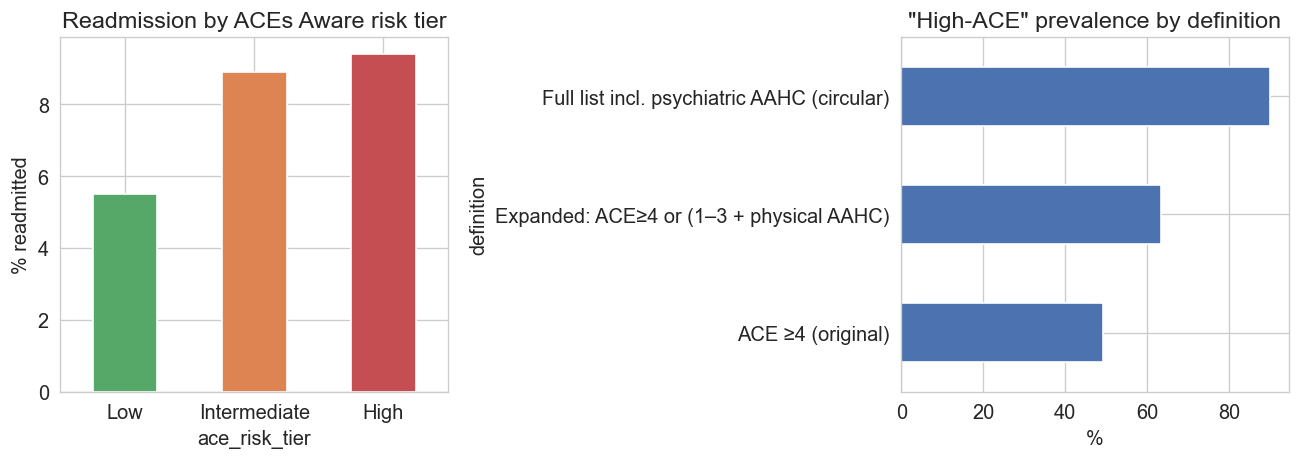


Note: the expanded definition does not strengthen the ACE–readmission gradient; ACE remains a weak/non-significant predictor either way (consistent with §3).


In [22]:
# Readmission by ACEs Aware risk tier + comparison of original vs expanded high-ACE
order=['Low','Intermediate','High']
tier=av.groupby('ace_risk_tier')['readmitted'].agg(['mean','count']).reindex(order)
tier['readmit_%']=(tier['mean']*100).round(1)
print('Readmission by ACEs Aware pediatric risk tier:'); print(tier[['count','readmit_%']].to_string())
o_hi=odds_ratio_2x2((av.ace_score>=4).astype(int).rename('x').reset_index(drop=True),'readmitted') if False else None
import statsmodels.formula.api as smf
m_orig=smf.logit('readmitted ~ I((ace_score>=4).astype(float))', data=av).fit(disp=0)
m_exp =smf.logit('readmitted ~ high_ace_expanded', data=av).fit(disp=0)
print(f"\nReadmission OR — original ACE>=4: {np.exp(m_orig.params.iloc[1]):.2f} (p={pstr(m_orig.pvalues.iloc[1])})")
print(f"Readmission OR — expanded high-ACE: {np.exp(m_exp.params['high_ace_expanded']):.2f} (p={pstr(m_exp.pvalues['high_ace_expanded'])})")
# adjusted: swap expanded def into the multivariable model
m_adj=smf.logit('readmitted ~ age+gender_male+insurance_public+had_restraints+n_dsm5_categories+has_depression+has_suicidal_ideation+high_ace_expanded', data=av).fit(disp=0,maxiter=300)
print(f"Adjusted (multivariable) expanded high-ACE OR: {np.exp(m_adj.params['high_ace_expanded']):.2f} (p={pstr(m_adj.pvalues['high_ace_expanded'])})")
fig,ax=plt.subplots(1,2,figsize=(11,4))
tier['readmit_%'].plot.bar(ax=ax[0],color=[GREEN,ORANGE,RED]); ax[0].set_title('Readmission by ACEs Aware risk tier'); ax[0].set_ylabel('% readmitted'); ax[0].tick_params(axis='x',rotation=0)
defs.set_index('definition')['high_%'].plot.barh(ax=ax[1],color=BLUE); ax[1].set_title('"High-ACE" prevalence by definition'); ax[1].set_xlabel('%')
plt.tight_layout(); plt.savefig('figures/Biv_13_ace_expanded.png'); plt.show()
tier.to_csv('figures/Biv_13_ace_risk_tiers.csv'); defs.to_csv('figures/Biv_13_highace_definitions.csv',index=False)
print('\nNote: the expanded definition does not strengthen the ACE–readmission gradient; ACE remains a weak/non-significant predictor either way (consistent with §3).')

## §3B — Diagnostic complexity measured two ways
"Diagnostic complexity" can mean the number of **distinct ICD-10 diagnoses** a child carries or the
number of distinct **DSM-5 categories** those diagnoses span — a coarser count. Throughout the rest of
the analysis `n_dsm5_categories` is the **category** count; here we add `n_distinct_diagnoses` (the
count of distinct ICD codes) and analyze both against readmission and length of stay, since the two
can diverge (e.g., three depressive codes are three diagnoses but one category).

n_dsm5_categories : median 3 (IQR 2-4, max 10)
n_distinct_diagnoses: median 6 (IQR 4-10, max 51)
Spearman(distinct dx, categories) rho=0.58

Each complexity measure vs outcomes (univariate):
               measure  OR_readmit p_readmit  rho_LOS  p_LOS
Distinct ICD diagnoses       1.058    <0.001    0.121 <0.001
      DSM-5 categories       1.446    <0.001    0.122 <0.001

Adjusted readmission OR — DSM-5 categories: 1.359 (p=<0.001)
Adjusted readmission OR — distinct diagnoses: 1.048 (p=<0.001)


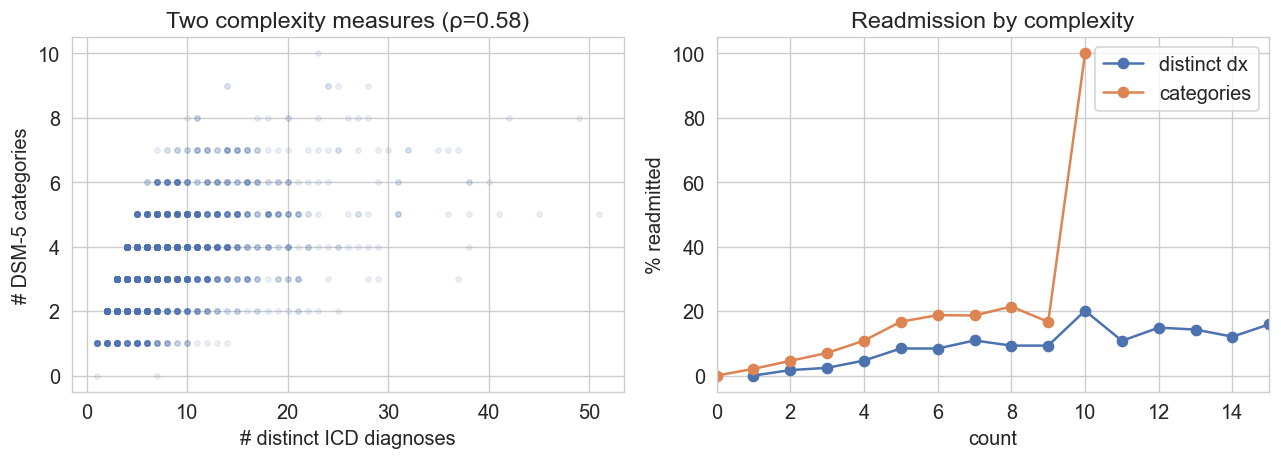

In [23]:
# Compare the two complexity measures and their associations
print('n_dsm5_categories : median %.0f (IQR %.0f-%.0f, max %d)'%(df.n_dsm5_categories.median(),df.n_dsm5_categories.quantile(.25),df.n_dsm5_categories.quantile(.75),df.n_dsm5_categories.max()))
print('n_distinct_diagnoses: median %.0f (IQR %.0f-%.0f, max %d)'%(df.n_distinct_diagnoses.median(),df.n_distinct_diagnoses.quantile(.25),df.n_distinct_diagnoses.quantile(.75),df.n_distinct_diagnoses.max()))
rho=spear(df.n_distinct_diagnoses, df.n_dsm5_categories); print(f'Spearman(distinct dx, categories) rho={rho["rho"]:.2f}')
rows=[]
for col,lab in [('n_distinct_diagnoses','Distinct ICD diagnoses'),('n_dsm5_categories','DSM-5 categories')]:
    mu=smf.logit(f'readmitted ~ {col}',data=df).fit(disp=0)
    los=spear(df[col], df.los_days)
    rows.append(dict(measure=lab, OR_readmit=round(np.exp(mu.params[col]),3), p_readmit=pstr(mu.pvalues[col]),
                     rho_LOS=round(los['rho'],3), p_LOS=pstr(los['p'])))
comp=pd.DataFrame(rows); comp.to_csv('figures/Biv_14_complexity_measures.csv',index=False)
print('\nEach complexity measure vs outcomes (univariate):'); print(comp.to_string(index=False))
# adjusted: swap distinct-diagnoses into the multivariable readmission model (vs categories)
m_cat =smf.logit('readmitted ~ age+gender_male+insurance_public+had_restraints+has_depression+has_suicidal_ideation+n_dsm5_categories',data=df).fit(disp=0,maxiter=300)
m_dx  =smf.logit('readmitted ~ age+gender_male+insurance_public+had_restraints+has_depression+has_suicidal_ideation+n_distinct_diagnoses',data=df).fit(disp=0,maxiter=300)
print(f"\nAdjusted readmission OR — DSM-5 categories: {np.exp(m_cat.params['n_dsm5_categories']):.3f} (p={pstr(m_cat.pvalues['n_dsm5_categories'])})")
print(f"Adjusted readmission OR — distinct diagnoses: {np.exp(m_dx.params['n_distinct_diagnoses']):.3f} (p={pstr(m_dx.pvalues['n_distinct_diagnoses'])})")
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(df.n_distinct_diagnoses,df.n_dsm5_categories,alpha=.1,s=10,color=BLUE); ax[0].set_xlabel('# distinct ICD diagnoses'); ax[0].set_ylabel('# DSM-5 categories'); ax[0].set_title(f'Two complexity measures (ρ={rho["rho"]:.2f})')
for col,c,l in [('n_distinct_diagnoses',BLUE,'distinct dx'),('n_dsm5_categories',ORANGE,'categories')]:
    g=df.groupby(col)['readmitted'].mean()*100; ax[1].plot(g.index,g.values,marker='o',color=c,label=l)
ax[1].set_xlabel('count'); ax[1].set_ylabel('% readmitted'); ax[1].set_title('Readmission by complexity'); ax[1].legend(); ax[1].set_xlim(0,15)
plt.tight_layout(); plt.savefig('figures/Biv_14_complexity_measures.png'); plt.show()

## §4 — Readmission windows, readmission LOS & time-to-readmission
**⚠ PRELIMINARY SUBSET.** Uses the 1,920-encounter Excel extract (`2025 data/Psychiatry_readmissions_cleaned.xlsx`),
of which **1,206 patients (1,415 encounters) link** to the complete cohort via `Account`→`MRN`.
This is NOT the full 2,652-patient cohort. **Readmission windows are defined from DISCHARGE**
(the standard convention) as the primary measure, shown against the file's precomputed flags for
validation and against an from-initial-admission version for reference. *Time from initial admission
to readmission* is reported separately as its own metric. Readmission-stay LOS is available for only
a handful of encounters (most `ReadmitDcDtm` are blank).

In [24]:
# Load XLSX, parse dates, link to canonical predictors
xl = pd.read_excel('2025 data/Psychiatry_readmissions_cleaned.xlsx')
bridge = pd.read_csv('With Ages GD1854RVSD_Psychiatric Rehospitalization In School-Aged Children(GD1854_RVSD).csv', header=2)
def xl_date(s):
    return pd.to_datetime(s, unit='D', origin='1899-12-30', errors='coerce') if pd.api.types.is_numeric_dtype(s) else pd.to_datetime(s, errors='coerce')
for c in ['AdmitDtm','DischargeDtm','ReadmitAdmDtm','ReadmitDcDtm']:
    xl[c+'_dt']=xl_date(xl[c])
xl['has_readmit']=(xl['HasReadmit'].astype(str).str.strip().str.lower()=='yes').astype(int)
xl['days_to_readmit_adm']=(xl['ReadmitAdmDtm_dt']-xl['AdmitDtm_dt']).dt.days
xl['days_to_readmit_dc'] =(xl['ReadmitAdmDtm_dt']-xl['DischargeDtm_dt']).dt.days
xl['readmit_los']=(xl['ReadmitDcDtm_dt']-xl['ReadmitAdmDtm_dt']).dt.days
xl['index_los']=pd.to_numeric(xl['LOSDays'],errors='coerce')
xl['Account']=pd.to_numeric(xl['Account'],errors='coerce')
bridge['Account']=pd.to_numeric(bridge['Account'],errors='coerce')
acc2mrn=bridge.dropna(subset=['Account']).set_index('Account')['MRN'].to_dict()
xl['MRN']=xl['Account'].map(acc2mrn)
linked=xl[xl['MRN'].notna()].copy()
cpred=df[['MRN','ace_score','ace_high','high_ace_expanded','had_restraints','csrss_any','insurance_public','has_depression','has_adhd','has_trauma','n_dsm5_categories']].copy()
linked=linked.merge(cpred,on='MRN',how='left')
NXL=len(xl)
print(f'XLSX encounters={NXL} | HasReadmit={xl.has_readmit.sum()} | linked encounters={len(linked)} ({linked.MRN.nunique()} patients) | ACE in linked={linked.ace_score.notna().sum()}')

XLSX encounters=1920 | HasReadmit=322 | linked encounters=1415 (1206 patients) | ACE in linked=1323


Readmission window ladder (PRELIMINARY SUBSET, N=1920) — PRIMARY = from discharge:
      from_discharge_%  precomputed_%  from_admission_%
7d                 1.2            1.2               0.4
30d                4.0            4.1               2.4
90d                7.6            6.9               7.3
180d              10.5            9.8              10.5
365d              13.5           12.9              13.6


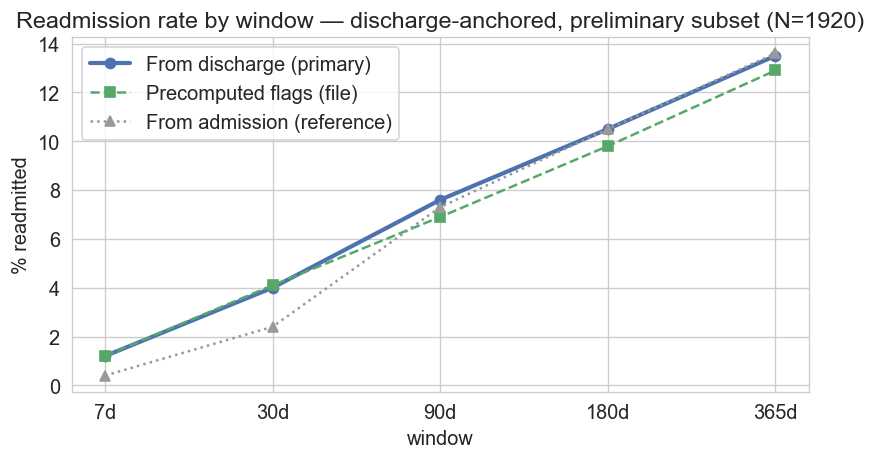

In [25]:
# Window ladder: from-admission vs from-discharge vs precomputed
def win_rate(days_col, w):
    return ((xl['has_readmit']==1)&(xl[days_col]>=0)&(xl[days_col]<=w)).mean()*100
WINS=[7,30,90,180,365]
ladder=pd.DataFrame({
 'from_discharge_%':[round(win_rate('days_to_readmit_dc',w),1) for w in WINS],          # PRIMARY (standard definition)
 'precomputed_%':[round(pd.to_numeric(xl[c],errors='coerce').fillna(0).mean()*100,1) for c in ['Readmit7Days','Readmit30Days','Readmit 90 days','Readmit 180 days','Readmit 365 days']],
 'from_admission_%':[round(win_rate('days_to_readmit_adm',w),1) for w in WINS],          # reference only
}, index=[f'{w}d' for w in WINS])
ladder.to_csv('figures/Win_rate_ladder.csv')
print('Readmission window ladder (PRELIMINARY SUBSET, N=%d) — PRIMARY = from discharge:'%NXL); print(ladder.to_string())
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(ladder.index, ladder['from_discharge_%'], marker='o', lw=2.5, color=BLUE, label='From discharge (primary)')
ax.plot(ladder.index, ladder['precomputed_%'], marker='s', ls='--', color=GREEN, label='Precomputed flags (file)')
ax.plot(ladder.index, ladder['from_admission_%'], marker='^', ls=':', color='0.6', label='From admission (reference)')
ax.set_ylabel('% readmitted'); ax.set_xlabel('window'); ax.legend()
ax.set_title('Readmission rate by window — discharge-anchored, preliminary subset (N=%d)'%NXL); plt.tight_layout(); plt.savefig('figures/Win_rate_ladder.png'); plt.show()

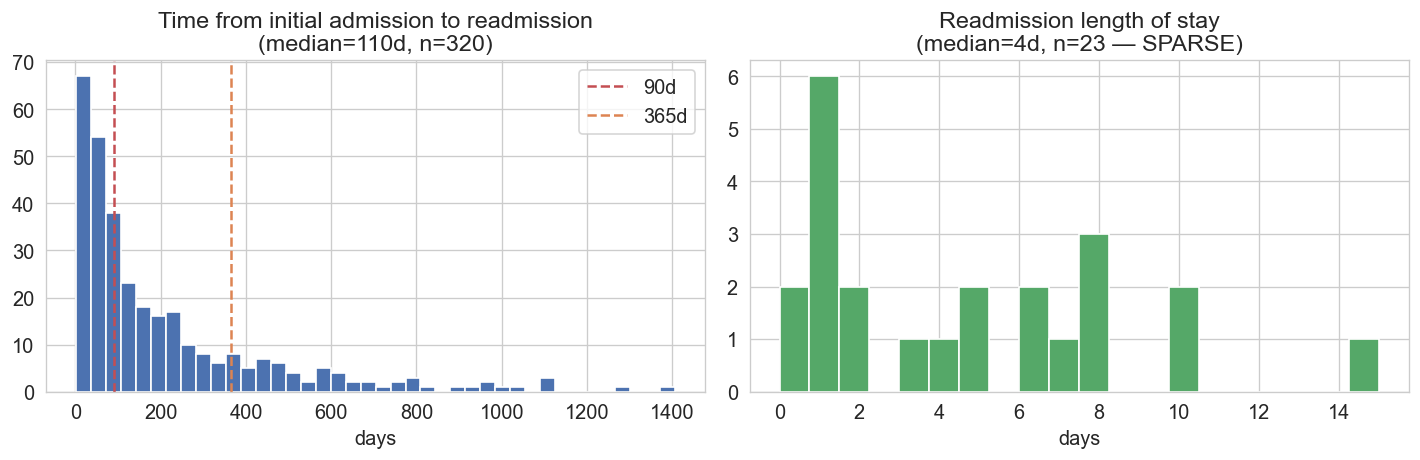

Time-to-readmit (from admission): median=110d (n=320); readmit LOS available n=23


In [26]:
# Time-to-readmission & readmission-LOS distributions (preliminary subset)
re_only=xl[xl.has_readmit==1]
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(re_only['days_to_readmit_adm'].dropna(),bins=40,color=BLUE); ax[0].axvline(90,color=RED,ls='--',label='90d'); ax[0].axvline(365,color=ORANGE,ls='--',label='365d')
ax[0].set_title(f'Time from initial admission to readmission\n(median={re_only.days_to_readmit_adm.median():.0f}d, n={re_only.days_to_readmit_adm.notna().sum()})'); ax[0].set_xlabel('days'); ax[0].legend()
rl=re_only['readmit_los'].dropna()
ax[1].hist(rl,bins=20,color=GREEN); ax[1].set_title(f'Readmission length of stay\n(median={rl.median():.0f}d, n={len(rl)} — SPARSE)'); ax[1].set_xlabel('days')
plt.tight_layout(); plt.savefig('figures/Win_distributions.png'); plt.show()
print(f'Time-to-readmit (from admission): median={re_only.days_to_readmit_adm.median():.0f}d (n={re_only.days_to_readmit_adm.notna().sum()}); readmit LOS available n={len(rl)}')

In [27]:
# Window rates by linked predictor (does ACE/restraint/diagnosis shift 90/365-day readmission?)
# Discharge-anchored (primary definition), consistent with the ladder above.
def wflag(w): return ((linked['has_readmit']==1)&(linked['days_to_readmit_dc']>=0)&(linked['days_to_readmit_dc']<=w)).astype(int)
linked['re90']=wflag(90); linked['re365']=wflag(365)
strat=[]
for name,mask in [('High ACE (expanded)',linked['high_ace_expanded']==1),('Not high ACE',linked['high_ace_expanded']==0),
                  ('Restrained',linked['had_restraints']==1),('No restraint',linked['had_restraints']==0),
                  ('Depression',linked['has_depression']==1),('ADHD',linked['has_adhd']==1)]:
    g=linked[mask]
    strat.append(dict(group=name,n=len(g),re90_pct=round(g['re90'].mean()*100,1),re365_pct=round(g['re365'].mean()*100,1)))
strat=pd.DataFrame(strat); strat.to_csv('figures/Win_by_predictor.csv',index=False)
print('90/365-day readmission by predictor (linked subset):'); print(strat.to_string(index=False))

90/365-day readmission by predictor (linked subset):
              group    n  re90_pct  re365_pct
High ACE (expanded)  843       7.6       12.7
       Not high ACE  480       6.9       12.1
         Restrained  199       7.5       14.6
       No restraint 1216       7.1       12.0
         Depression 1013       7.9       13.2
               ADHD  754       7.2       13.9


## §5 — Psychiatrist vs Nurse Practitioner (exploratory, preliminary subset)
**⚠ EXPLORATORY / UNDERPOWERED.** The provider field exists only in the preliminary XLSX, with
**1,894 psychiatrist vs 26 NP encounters**. Comparisons are descriptive with caveated tests; the
NP group is far too small for reliable inference.

PSYCHIATRIST vs NP (EXPLORATORY, n_NP=26 — underpowered):
        metric  Psychiatrist    NP         test     p
  n encounters       1894.00 26.00            —     —
LOS median (d)          8.00  9.00 Mann-Whitney 0.230
     Readmit %         16.80 15.40   chi-square 1.000
    CMI median          1.24  1.23 Mann-Whitney 0.910
    Age median         10.00 10.00 Mann-Whitney 0.149


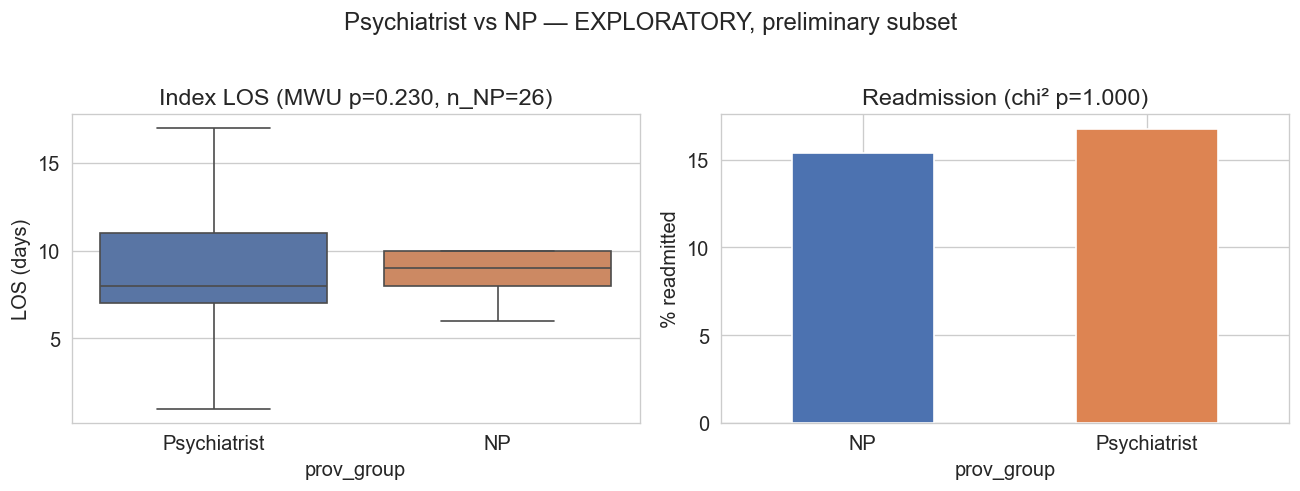

In [28]:
# Provider groups + comparisons
xl['prov_group']=xl['AttendingSpecialty'].apply(lambda s:'NP' if 'NP' in str(s).upper() else ('Psychiatrist' if 'PSYCH' in str(s).upper() else 'Other'))
g=xl[xl.prov_group.isin(['Psychiatrist','NP'])].copy()
psy,npg=g[g.prov_group=='Psychiatrist'],g[g.prov_group=='NP']
los_r=mwu(psy.index_los,npg.index_los)
re_tab=chi2(g.prov_group,g.has_readmit)
cmi_r=mwu(pd.to_numeric(psy.get('CMI'),errors='coerce'),pd.to_numeric(npg.get('CMI'),errors='coerce'))
age_r=mwu(pd.to_numeric(psy.get('AgeYears'),errors='coerce'),pd.to_numeric(npg.get('AgeYears'),errors='coerce'))
summary=pd.DataFrame([
 dict(metric='n encounters',Psychiatrist=len(psy),NP=len(npg),test='—',p='—'),
 dict(metric='LOS median (d)',Psychiatrist=round(los_r['med1'],1),NP=round(los_r['med2'],1),test='Mann-Whitney',p=pstr(los_r['p'])),
 dict(metric='Readmit %',Psychiatrist=round(psy.has_readmit.mean()*100,1),NP=round(npg.has_readmit.mean()*100,1),test='chi-square',p=pstr(re_tab['p'])),
 dict(metric='CMI median',Psychiatrist=round(cmi_r['med1'],2),NP=round(cmi_r['med2'],2),test='Mann-Whitney',p=pstr(cmi_r['p'])),
 dict(metric='Age median',Psychiatrist=round(age_r['med1'],1),NP=round(age_r['med2'],1),test='Mann-Whitney',p=pstr(age_r['p'])),
])
summary.to_csv('figures/Prov_comparison.csv',index=False)
print('PSYCHIATRIST vs NP (EXPLORATORY, n_NP=26 — underpowered):'); print(summary.to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=g,x='prov_group',y='index_los',ax=ax[0],showfliers=False,palette=[BLUE,ORANGE]); ax[0].set_title(f'Index LOS (MWU p={pstr(los_r["p"])}, n_NP=26)'); ax[0].set_ylabel('LOS (days)')
g.groupby('prov_group')['has_readmit'].mean().mul(100).plot.bar(ax=ax[1],color=[BLUE,ORANGE]); ax[1].set_ylabel('% readmitted'); ax[1].set_title(f'Readmission (chi² p={pstr(re_tab["p"])})'); ax[1].tick_params(axis='x',rotation=0)
plt.suptitle('Psychiatrist vs NP — EXPLORATORY, preliminary subset',y=1.02); plt.tight_layout(); plt.savefig('figures/Prov_comparison.png'); plt.show()

## §6 — ML / predictive augmentation
Random Forest and CatBoost (vs logistic baseline) predicting **readmission**, using the established
features plus new ones (reclassified **neurocognitive** flag, restraint count, full DSM-5 category
set). Performance is reported **out-of-fold** (10-fold stratified CV) to avoid optimism; in-sample
tree AUCs are not trustworthy. A bootstrap test compares the augmented feature set to the baseline.

> Consistent with the project's documented predictive ceiling (out-of-fold AUC ≈ 0.68): these
> models characterize risk factors but cannot triage individuals.

In [29]:
# Build feature matrix (baseline + augmented) with imputation
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from catboost import CatBoostClassifier

BASE_FEATS = ['age','gender_male','insurance_public','had_restraints','csrss_any','los_days',
              'n_dsm5_categories','has_depression','has_trauma','has_adhd','has_nssi',
              'has_asd','has_conduct','has_bipolar','has_psychotic']
NEW_FEATS  = ['restraint_n','has_neurocognitive','has_suicidal_ideation','has_anxiety','has_intellectual','has_ocd','high_ace_expanded']
ALL_FEATS  = BASE_FEATS + NEW_FEATS

Xa = df[ALL_FEATS].copy()
imp = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50,random_state=42),max_iter=10,random_state=42)
Xa[['age','los_days']] = imp.fit_transform(Xa[['age','los_days']])
Xa = Xa.fillna(0)
yv = df['readmitted'].values
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
print(f'Feature matrix: {Xa.shape}; readmit prevalence={yv.mean():.1%}; {len(BASE_FEATS)} base + {len(NEW_FEATS)} new feats')

Feature matrix: (2652, 22); readmit prevalence=9.3%; 15 base + 7 new feats


Logistic       OOF AUC=0.683  AP=0.178
RandomForest   OOF AUC=0.695  AP=0.180
CatBoost       OOF AUC=0.656  AP=0.161


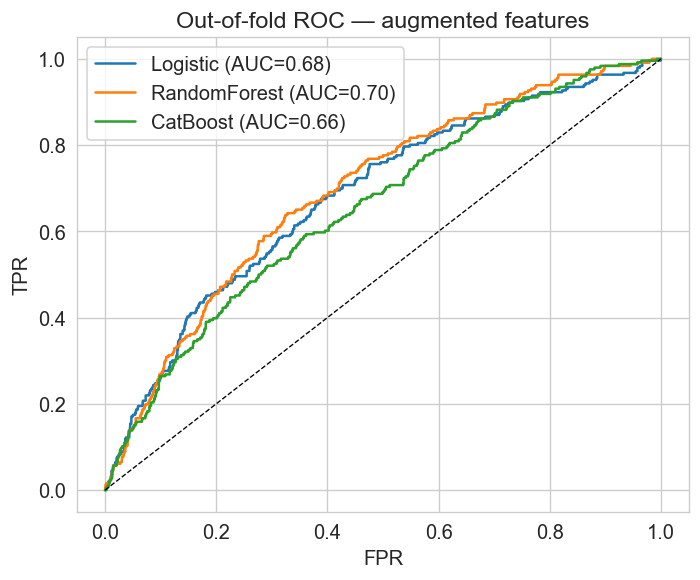

In [30]:
# Out-of-fold AUC/AP for LR, RF, CatBoost (augmented feature set)
def oof(model, X):
    p = cross_val_predict(model, X, yv, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
    return p, roc_auc_score(yv,p), average_precision_score(yv,p)
models = {
 'Logistic': LogisticRegression(max_iter=2000, class_weight='balanced'),
 'RandomForest': RandomForestClassifier(n_estimators=400,max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=42,n_jobs=-1),
 'CatBoost': CatBoostClassifier(iterations=400,depth=6,learning_rate=0.05,loss_function='Logloss',random_state=42,verbose=False),
}
perf={}; probs={}
for name,mdl in models.items():
    Xs = StandardScaler().fit_transform(Xa) if name=='Logistic' else Xa.values
    p,auc,ap = oof(mdl, Xs); perf[name]=(auc,ap); probs[name]=p
    print(f'{name:14s} OOF AUC={auc:.3f}  AP={ap:.3f}')
perf_df=pd.DataFrame(perf,index=['AUC','AP']).T; perf_df.to_csv('figures/MLx_oof_performance.csv')
fig,ax=plt.subplots(figsize=(6,5))
for name,p in probs.items():
    fpr,tpr,_=roc_curve(yv,p); ax.plot(fpr,tpr,label=f'{name} (AUC={perf[name][0]:.2f})')
ax.plot([0,1],[0,1],'k--',lw=.8); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend()
ax.set_title('Out-of-fold ROC — augmented features'); plt.tight_layout(); plt.savefig('figures/MLx_roc.png'); plt.show()

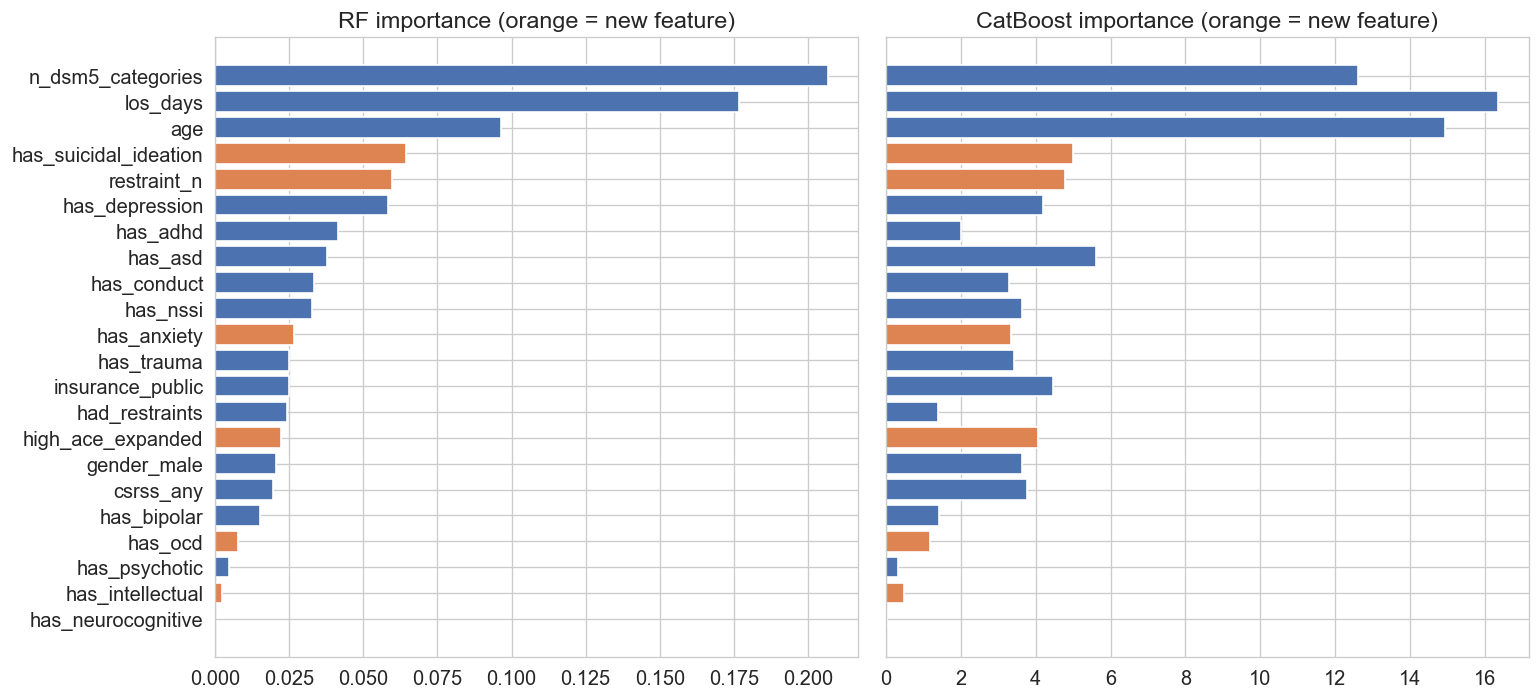

                          RF  CatBoost  is_new
feature                                       
n_dsm5_categories      0.207    12.609   False
los_days               0.177    16.342   False
age                    0.096    14.934   False
has_suicidal_ideation  0.064     4.989    True
restraint_n            0.060     4.797    True
has_depression         0.058     4.202   False
has_adhd               0.042     2.009   False
has_asd                0.038     5.615   False
has_conduct            0.033     3.284   False
has_nssi               0.033     3.637   False
has_anxiety            0.027     3.339    True
has_trauma             0.025     3.412   False
insurance_public       0.025     4.472   False
had_restraints         0.024     1.409   False
high_ace_expanded      0.022     4.067    True
gender_male            0.021     3.641   False
csrss_any              0.019     3.766   False
has_bipolar            0.015     1.436   False
has_ocd                0.008     1.184    True
has_psychotic

In [31]:
# Feature importance: RF + CatBoost (fit on full data)
rf=RandomForestClassifier(n_estimators=400,max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=42,n_jobs=-1).fit(Xa,yv)
cb=CatBoostClassifier(iterations=400,depth=6,learning_rate=0.05,random_state=42,verbose=False).fit(Xa,yv)
imp_df=pd.DataFrame({'feature':ALL_FEATS,'RF':rf.feature_importances_,'CatBoost':cb.feature_importances_}).set_index('feature')
imp_df['is_new']=[f in NEW_FEATS for f in imp_df.index]
imp_df.to_csv('figures/MLx_feature_importance.csv')
fig,ax=plt.subplots(1,2,figsize=(13,6),sharey=True)
for a,col in zip(ax,['RF','CatBoost']):
    s=imp_df[col].sort_values()
    a.barh(s.index, s.values, color=[ORANGE if imp_df.loc[f,'is_new'] else BLUE for f in s.index])
    a.set_title(f'{col} importance (orange = new feature)')
plt.tight_layout(); plt.savefig('figures/MLx_feature_importance.png'); plt.show()
print(imp_df.sort_values('RF',ascending=False).round(3).to_string())

In [32]:
# SHAP summary (RandomForest) — robust to failure
try:
    import shap
    expl=shap.TreeExplainer(rf)
    samp=Xa.sample(min(400,len(Xa)),random_state=42)
    sv=expl.shap_values(samp)
    sv1=sv[1] if isinstance(sv,list) else sv
    plt.figure(); shap.summary_plot(sv1, samp, show=False, max_display=15)
    plt.title('SHAP summary — Random Forest (readmission)'); plt.tight_layout(); plt.savefig('figures/MLx_shap_rf.png',bbox_inches='tight'); plt.close()
    print('✓ SHAP summary saved → figures/MLx_shap_rf.png')
except Exception as e:
    print('SHAP skipped:', str(e)[:100])

✓ SHAP summary saved → figures/MLx_shap_rf.png


<Figure size 768x576 with 0 Axes>

In [33]:
# Bootstrap: does the augmented feature set beat the baseline (RF, OOF AUC)?
def oof_auc(cols):
    Xm=Xa[cols].values
    p=cross_val_predict(RandomForestClassifier(n_estimators=400,max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=42,n_jobs=-1),Xm,yv,cv=cv,method='predict_proba',n_jobs=-1)[:,1]
    return p
p_base=oof_auc(BASE_FEATS); p_aug=oof_auc(ALL_FEATS)
auc_base,auc_aug=roc_auc_score(yv,p_base),roc_auc_score(yv,p_aug)
rng=np.random.RandomState(42); diffs=[]
idx=np.arange(len(yv))
for _ in range(2000):
    b=rng.choice(idx,len(idx),replace=True)
    if yv[b].sum()<5: continue
    diffs.append(roc_auc_score(yv[b],p_aug[b])-roc_auc_score(yv[b],p_base[b]))
diffs=np.array(diffs); lo,hi=np.percentile(diffs,[2.5,97.5]); pval=2*min((diffs<=0).mean(),(diffs>=0).mean())
print(f'Baseline RF OOF AUC={auc_base:.3f} | Augmented={auc_aug:.3f} | Δ={auc_aug-auc_base:+.3f} (95% CI {lo:+.3f},{hi:+.3f}), bootstrap p={pstr(pval)}')
print('Interpretation: new features add little discrimination — consistent with the ~0.68 predictive ceiling.')

Baseline RF OOF AUC=0.685 | Augmented=0.695 | Δ=+0.010 (95% CI -0.005,+0.024), bootstrap p=0.179
Interpretation: new features add little discrimination — consistent with the ~0.68 predictive ceiling.


## §7 — Self-harm spectrum & systematic individual-ICD-code analysis
Earlier tiers worked at the DSM-5 *category* and ICD *chapter* level, which can dilute high-risk
individual codes. This section (a) separates the **self-harm spectrum** (ideation vs attempt vs
history) instead of merging it into one "suicidality" variable, and (b) sweeps **every ICD-10 code with
n≥30** to surface individual codes the category view hides — including a flag for codes that are
significant individually but whose DSM-5 category is not.

Self-harm spectrum (ICD codes) — distinct constructs, NOT one "suicidality" variable:
                                    measure    n  readmit_with  readmit_without  uni_OR  uni_p  adj_OR adj_p  LOS_p
                Suicidal ideation (R45.851) 1346          11.4              7.1    1.67 <0.001    1.47 0.010 <0.001
Suicide attempt / self-harm injury (T14.91)  119          10.1              9.2    1.14  0.669    1.34 0.370  0.051
               History of self-harm (Z91.5)   42          21.4              9.1    2.83  0.005    2.82 0.010  0.035
      Any attempt or history (T14.91/Z91.5)  154          12.3              9.1    1.44  0.150    1.67 0.059      —


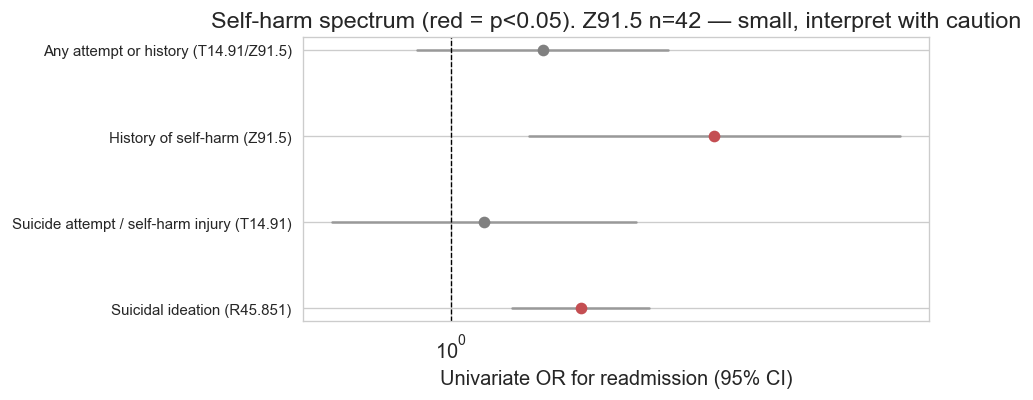


Key point: history of self-harm (Z91.5) carries the strongest signal but is rare (n=42);
ideation (R45.851) is common and moderate; a documented attempt code (T14.91) is not significant here.


In [34]:
# §7A — Self-harm / suicidality spectrum: ideation vs attempt vs history (univariate + adjusted)
from statsmodels.stats.contingency_tables import Table2x2
def _hald_or(flag):
    a=int(((flag==1)&(df.readmitted==1)).sum()); b=int(((flag==1)&(df.readmitted==0)).sum())
    c=int(((flag==0)&(df.readmitted==1)).sum()); e=int(((flag==0)&(df.readmitted==0)).sum())
    t=Table2x2(np.array([[a+0.5,b+0.5],[c+0.5,e+0.5]])); ci=t.oddsratio_confint()
    return t.oddsratio, ci[0], ci[1], t.oddsratio_pvalue()
_BASE='readmitted ~ age+gender_male+insurance_public+had_restraints+csrss_any+los_days+n_dsm5_categories+has_depression'
_spec={'Suicidal ideation (R45.851)':'R45.851','Suicide attempt / self-harm injury (T14.91)':'T14.91','History of self-harm (Z91.5)':'Z91.5'}
rows=[]
for lbl,code in _spec.items():
    df['_f']=allcodes.str.contains(code,regex=False).astype(int)
    orr,lo,hi,p=_hald_or(df['_f']); m=smf.logit(_BASE+' + _f',data=df).fit(disp=0,maxiter=200)
    losp=mwu(df[df._f==1].los_days, df[df._f==0].los_days)['p']
    rows.append(dict(measure=lbl,n=int(df._f.sum()),readmit_with=round(df[df._f==1].readmitted.mean()*100,1),
        readmit_without=round(df[df._f==0].readmitted.mean()*100,1),uni_OR=round(orr,2),lo=lo,hi=hi,uni_p=pstr(p),
        adj_OR=round(np.exp(m.params['_f']),2),adj_p=pstr(m.pvalues['_f']),LOS_p=pstr(losp)))
df['_f']=(allcodes.str.contains('T14.91',regex=False)|allcodes.str.contains('Z91.5',regex=False)).astype(int)
orr,lo,hi,p=_hald_or(df['_f']); m=smf.logit(_BASE+' + _f',data=df).fit(disp=0,maxiter=200)
rows.append(dict(measure='Any attempt or history (T14.91/Z91.5)',n=int(df._f.sum()),readmit_with=round(df[df._f==1].readmitted.mean()*100,1),
    readmit_without=round(df[df._f==0].readmitted.mean()*100,1),uni_OR=round(orr,2),lo=lo,hi=hi,uni_p=pstr(p),
    adj_OR=round(np.exp(m.params['_f']),2),adj_p=pstr(m.pvalues['_f']),LOS_p='—'))
spec_df=pd.DataFrame(rows); spec_df.drop(columns=['lo','hi']).to_csv('figures/Spectrum_selfharm.csv',index=False)
print('Self-harm spectrum (ICD codes) — distinct constructs, NOT one "suicidality" variable:')
print(spec_df.drop(columns=['lo','hi']).to_string(index=False))
fig,ax=plt.subplots(figsize=(8,3.5)); yy=range(len(spec_df))
for i,r in spec_df.iterrows():
    cc=RED if ('<' in str(r['uni_p']) or float(str(r['uni_p']).replace('<','')) < 0.05) else '0.5'
    ax.plot([r['lo'],r['hi']],[i,i],color='0.6'); ax.plot(r['uni_OR'],i,'o',color=cc)
ax.set_yticks(list(yy)); ax.set_yticklabels(spec_df['measure'],fontsize=9); ax.axvline(1,color='k',ls='--',lw=.8); ax.set_xscale('log')
ax.set_xlabel('Univariate OR for readmission (95% CI)'); ax.set_title('Self-harm spectrum (red = p<0.05). Z91.5 n=42 — small, interpret with caution')
plt.tight_layout(); plt.savefig('figures/Spectrum_selfharm.png'); plt.show()
print('\nKey point: history of self-harm (Z91.5) carries the strongest signal but is rare (n=42);')
print('ideation (R45.851) is common and moderate; a documented attempt code (T14.91) is not significant here.')

Individual codes tested (n>=30): 115; FDR-significant: 19  (descriptions from the ICD->DSM5 mapping file)

Top elevated-risk individual codes (FDR<0.05):
   code    n  readmit_pct    OR    p_fdr                                                      description
  F94.1   92         22.8 3.114 0.000254       Reactive attachment disorder of infancy or early childhood
 R45.88   42         21.4 2.834 0.032240               Other symptoms and signs involving emotional state
  Z91.5   42         21.4 2.834 0.032240                                    Personal history of self-harm
 R06.83   52         21.2 2.783 0.021512                                                            Apnea
Z62.812   70         20.0 2.595 0.015449             Personal history of psychological abuse in childhood
  P04.9  102         19.6 2.550 0.003339               Newborn affected by maternal unspecified condition
  F32.A   69         18.8 2.405 0.031931 Major depressive disorder, single episode, with anxious distres

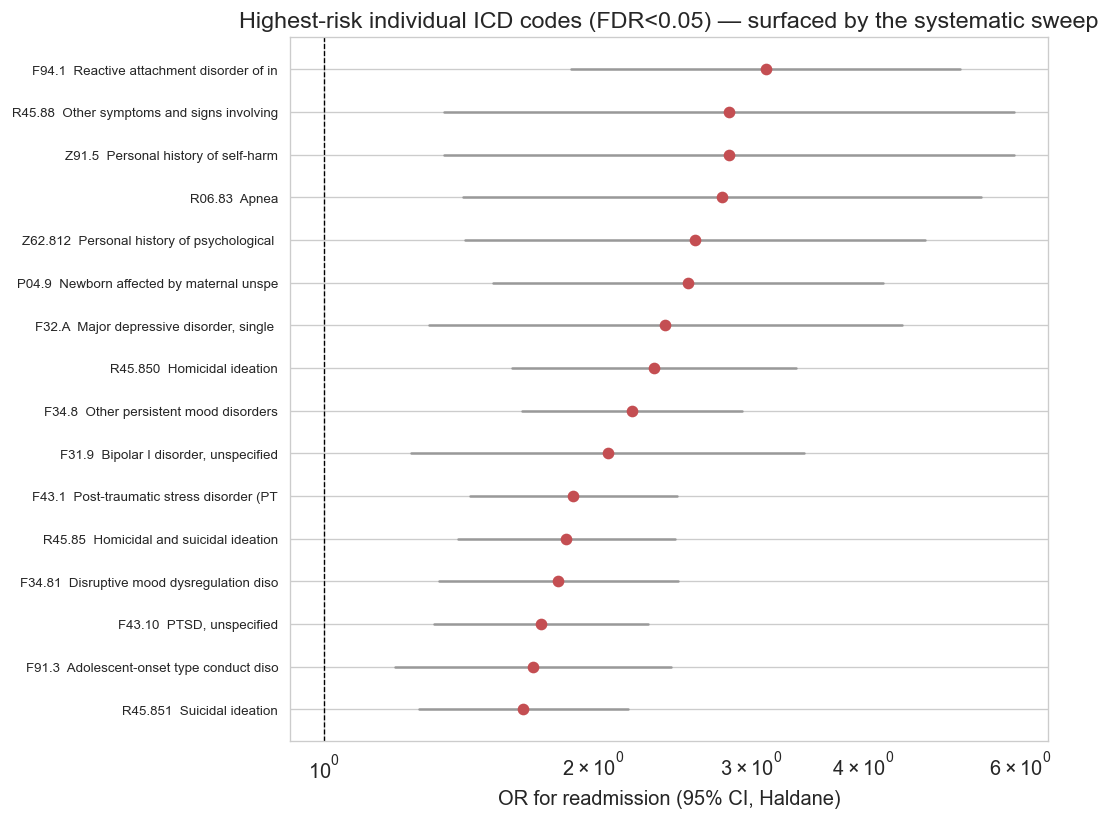

In [35]:
# §7B — Systematic individual-ICD-code sweep (all codes with n>=30) vs readmission
from collections import Counter
_cnt=Counter(t.strip() for s in allcodes for t in s.split(',') if t.strip())
_ref=pd.read_csv('ICD10_to_DSM5_Complete_Reference.csv').set_index('ICD_Code')
_desc=_ref['Description'].to_dict(); _dsm=_ref['DSM5_Category'].to_dict()
_desc.update({'Z91.5':'Personal history of self-harm'})   # mapping-file mislabels Z91.5 as 'noncompliance'
rows=[]
for c,n in _cnt.items():
    if n<30: continue
    f=allcodes.str.contains(c,regex=False).astype(int)
    if f.sum()<30: continue
    orr,lo,hi,p=_hald_or(f)
    rows.append(dict(code=c,n=int(f.sum()),readmit_pct=round(df[f==1].readmitted.mean()*100,1),OR=round(orr,3),lo=round(lo,3),hi=round(hi,3),p=p,
                     description=str(_desc.get(c,'')),dsm5_category=str(_dsm.get(c,''))))
sweep=pd.DataFrame(rows); sweep['p_fdr']=multipletests(sweep['p'],method='fdr_bh')[1]; sweep=sweep.sort_values('OR',ascending=False)
sweep.to_csv('figures/Code_sweep_readmission.csv',index=False)
sig=sweep[sweep['p_fdr']<0.05]
print(f'Individual codes tested (n>=30): {len(sweep)}; FDR-significant: {len(sig)}  (descriptions from the ICD->DSM5 mapping file)')
print('\nTop elevated-risk individual codes (FDR<0.05):')
print(sig.head(14)[['code','n','readmit_pct','OR','p_fdr','description']].to_string(index=False))
prot=sig[sig['OR']<1]
print(f'\nFDR-significant PROTECTIVE codes (OR<1): {len(prot)}' + ('' if len(prot) else ' — none; lowest significant ORs are still >1 (1.5-1.8 range).'))
# forest of top 16 by |log OR|
top=sig.reindex(sig['OR'].sort_values(ascending=False).index).head(16).iloc[::-1]
fig,ax=plt.subplots(figsize=(9,7)); yy=range(len(top))
for i,(_,r) in enumerate(top.iterrows()):
    ax.plot([r['lo'],r['hi']],[i,i],color='0.6'); ax.plot(r['OR'],i,'o',color=RED)
ax.set_yticks(list(yy)); ax.set_yticklabels([f"{r['code']}  {str(r['description'])[:34]}" for _,r in top.iterrows()],fontsize=8)
ax.axvline(1,color='k',ls='--',lw=.8); ax.set_xscale('log'); ax.set_xlabel('OR for readmission (95% CI, Haldane)')
ax.set_title('Highest-risk individual ICD codes (FDR<0.05) — surfaced by the systematic sweep')
plt.tight_layout(); plt.savefig('figures/Code_sweep_readmission.png'); plt.show()

In [36]:
# §7B (cont.) — LOST NUANCES: codes significant individually but whose DSM-5 category is NOT
catp={}
for cat in sweep['dsm5_category'].dropna().unique():
    if not str(cat).strip(): continue
    cf=all_dsm5.str.contains(str(cat).lower(),na=False).astype(int)
    if cf.sum()<30: continue
    catp[cat]=_hald_or(cf)[3]
lost=[]
for _,r in sig.iterrows():
    cat=r['dsm5_category']
    if cat and str(cat).strip() and cat in catp and catp[cat]>=0.05:
        lost.append(dict(code=r['code'],OR=r['OR'],description=r['description'][:40],dsm5_category=cat,category_p=round(catp[cat],3)))
lost_df=pd.DataFrame(lost); lost_df.to_csv('figures/Code_lost_nuances.csv',index=False)
print('LOST NUANCES — individually FDR-significant codes whose DSM-5 *category* is non-significant')
print('(these high-risk codes are diluted when collapsed to the category level):')
print(lost_df.to_string(index=False) if len(lost_df) else '  (none)')
# LOS sweep
rowsl=[]
for c,n in _cnt.items():
    if n<30: continue
    f=allcodes.str.contains(c,regex=False)
    if f.sum()<30: continue
    r=mwu(df[f].los_days, df[~f].los_days)
    rowsl.append(dict(code=c,n=int(f.sum()),median_with=r['med1'],median_without=r['med2'],dLOS=r['med1']-r['med2'],p=r['p'],description=str(_desc.get(c,''))))
losdf=pd.DataFrame(rowsl); losdf['p_fdr']=multipletests(losdf['p'].fillna(1),method='fdr_bh')[1]
losdf.sort_values('dLOS',ascending=False).to_csv('figures/Code_sweep_los.csv',index=False)
ls=losdf[losdf.p_fdr<0.05].sort_values('dLOS',ascending=False)
print(f'\nIndividual codes with FDR-significant LOS difference: {len(ls)}. Top longer-LOS:')
print(ls.head(8)[['code','n','dLOS','p_fdr','description']].to_string(index=False))

LOST NUANCES — individually FDR-significant codes whose DSM-5 *category* is non-significant
(these high-risk codes are diluted when collapsed to the category level):
   code    OR                              description                         dsm5_category  category_p
  F94.1 3.114 Reactive attachment disorder of infancy  Trauma and Stressor-Related Disorders       0.063
  F43.1 1.898    Post-traumatic stress disorder (PTSD) Trauma and Stressor-Related Disorders       0.063
 F43.10 1.748                        PTSD, unspecified Trauma and Stressor-Related Disorders       0.063
R45.851 1.669                        Suicidal ideation     Non-Suicidal Self-Injury Behavior       0.188

Individual codes with FDR-significant LOS difference: 35. Top longer-LOS:
  code   n  dLOS    p_fdr                                                description
 F91.1  34   2.5 0.008096                      Childhood-onset type conduct disorder
 K21.9  66   2.0 0.013846       Gastro-esophageal reflux disease

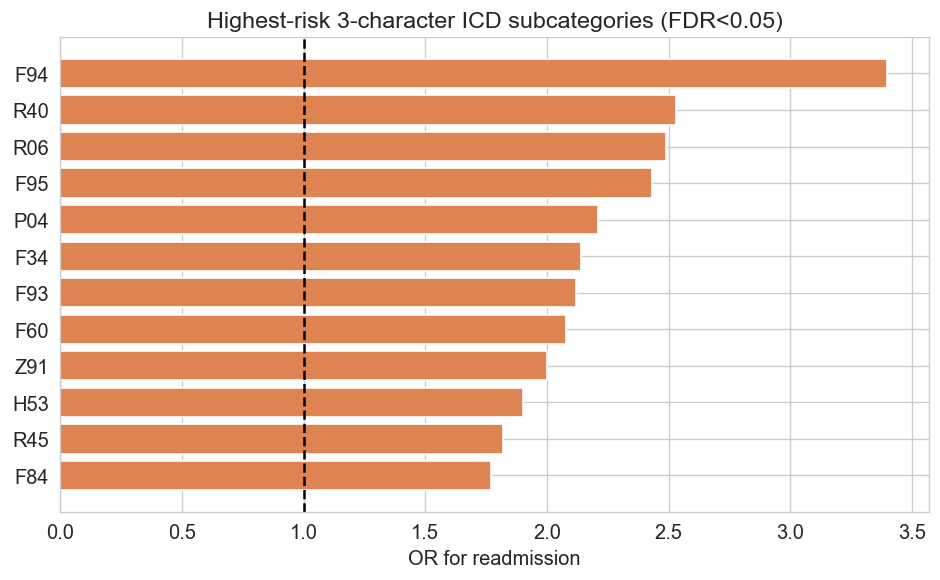

Top 3-char ICD subcategories by readmission OR (FDR<0.05):
prefix    n  readmit_pct   OR            p    p_fdr
   F94   99         24.2 3.40 4.672577e-07 0.000020
   R40   51         19.6 2.53 8.367863e-03 0.046860
   R06   62         19.4 2.49 4.817817e-03 0.031131
   F95   79         19.0 2.43 2.273522e-03 0.021220
   P04  126         17.5 2.21 1.097937e-03 0.011528
   F34  538         15.2 2.14 1.353941e-07 0.000011
   F93  161         16.8 2.12 6.866474e-04 0.008240
   F60  120         16.7 2.08 3.742238e-03 0.026196
   Z91  149         16.1 2.00 2.749160e-03 0.023093
   H53  142         15.5 1.90 7.419895e-03 0.044519
   R45 1557         11.2 1.82 4.292282e-05 0.001202
   F84  513         13.6 1.77 1.500960e-04 0.002522


In [37]:
# §7C — 3-character ICD subcategory layer (between chapter and individual code)
from collections import Counter
_p3=Counter()
for s in allcodes:
    for t in {x.strip()[:3] for x in s.split(',') if x.strip()}: _p3[t]+=1
rows=[]
for p3,n in _p3.items():
    if n<30: continue
    f=allcodes.apply(lambda s: any(x.strip().startswith(p3) for x in s.split(','))).astype(int)
    orr,lo,hi,p=_hald_or(f); rows.append(dict(prefix=p3,n=int(f.sum()),readmit_pct=round(df[f==1].readmitted.mean()*100,1),OR=round(orr,2),p=p))
sub3=pd.DataFrame(rows); sub3['p_fdr']=multipletests(sub3['p'],method='fdr_bh')[1]
sub3=sub3.sort_values('OR',ascending=False); sub3.to_csv('figures/Code_subcat3.csv',index=False)
topc=sub3[sub3.p_fdr<0.05].head(12)
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(topc['prefix'][::-1],topc['OR'][::-1],color=ORANGE); ax.axvline(1,color='k',ls='--')
ax.set_xlabel('OR for readmission'); ax.set_title('Highest-risk 3-character ICD subcategories (FDR<0.05)')
plt.tight_layout(); plt.savefig('figures/Code_subcat3.png'); plt.show()
print('Top 3-char ICD subcategories by readmission OR (FDR<0.05):'); print(topc.to_string(index=False))